In [1]:
import os

DATASET_PATH = "/kaggle/input"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

input/
    datasets/
        paramaggarwal/
            fashion-product-images-small/
                styles.csv


In [2]:
import os

DATASET_PATH = "/kaggle/input/datasets/paramaggarwal/fashion-product-images-small"

print("Dataset contents:\n")

for item in os.listdir(DATASET_PATH):
    path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(path):
        files = os.listdir(path)
        print(f"📁 {item} | {len(files):,} items")

    else:
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"📄 {item} | {size_mb:.2f} MB")

Dataset contents:

📁 images | 44,441 items
📁 myntradataset | 2 items
📄 styles.csv | 4.13 MB


---

# Cell 1 — Load Metadata

In [3]:
import pandas as pd
import numpy as np
import os

BASE_PATH = "/kaggle/input/datasets/paramaggarwal/fashion-product-images-small"

IMAGE_PATH = os.path.join(BASE_PATH, "images")
CSV_PATH = os.path.join(BASE_PATH, "styles.csv")

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (44424, 10)

Columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']

First 5 Records:


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


# Cell 2 — Dataset Information

In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate Records:")
print("Duplicate IDs:", df["id"].duplicated().sum())

print("Total Images:", len(os.listdir(IMAGE_PATH)))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  44424 non-null  int64  
 1   gender              44424 non-null  object 
 2   masterCategory      44424 non-null  object 
 3   subCategory         44424 non-null  object 
 4   articleType         44424 non-null  object 
 5   baseColour          44409 non-null  object 
 6   season              44403 non-null  object 
 7   year                44423 non-null  float64
 8   usage               44107 non-null  object 
 9   productDisplayName  44417 non-null  object 
dtypes: float64(1), int64(1), object(8)
memory usage: 3.4+ MB

Missing Values:


usage                 317
season                 21
baseColour             15
productDisplayName      7
year                    1
id                      0
gender                  0
articleType             0
masterCategory          0
subCategory             0
dtype: int64


Duplicate Records:
Duplicate IDs: 0
Total Images: 44441


# Cell 3 — Category Distribution

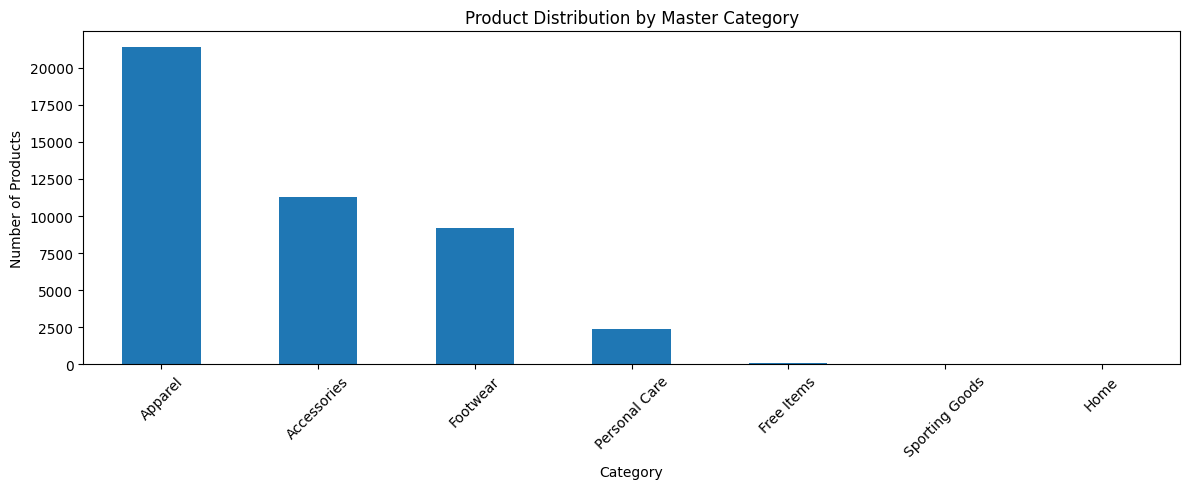

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

df["masterCategory"].value_counts().plot(
    kind="bar",
    title="Product Distribution by Master Category"
)

plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Cell 4 — Visualize Random Products

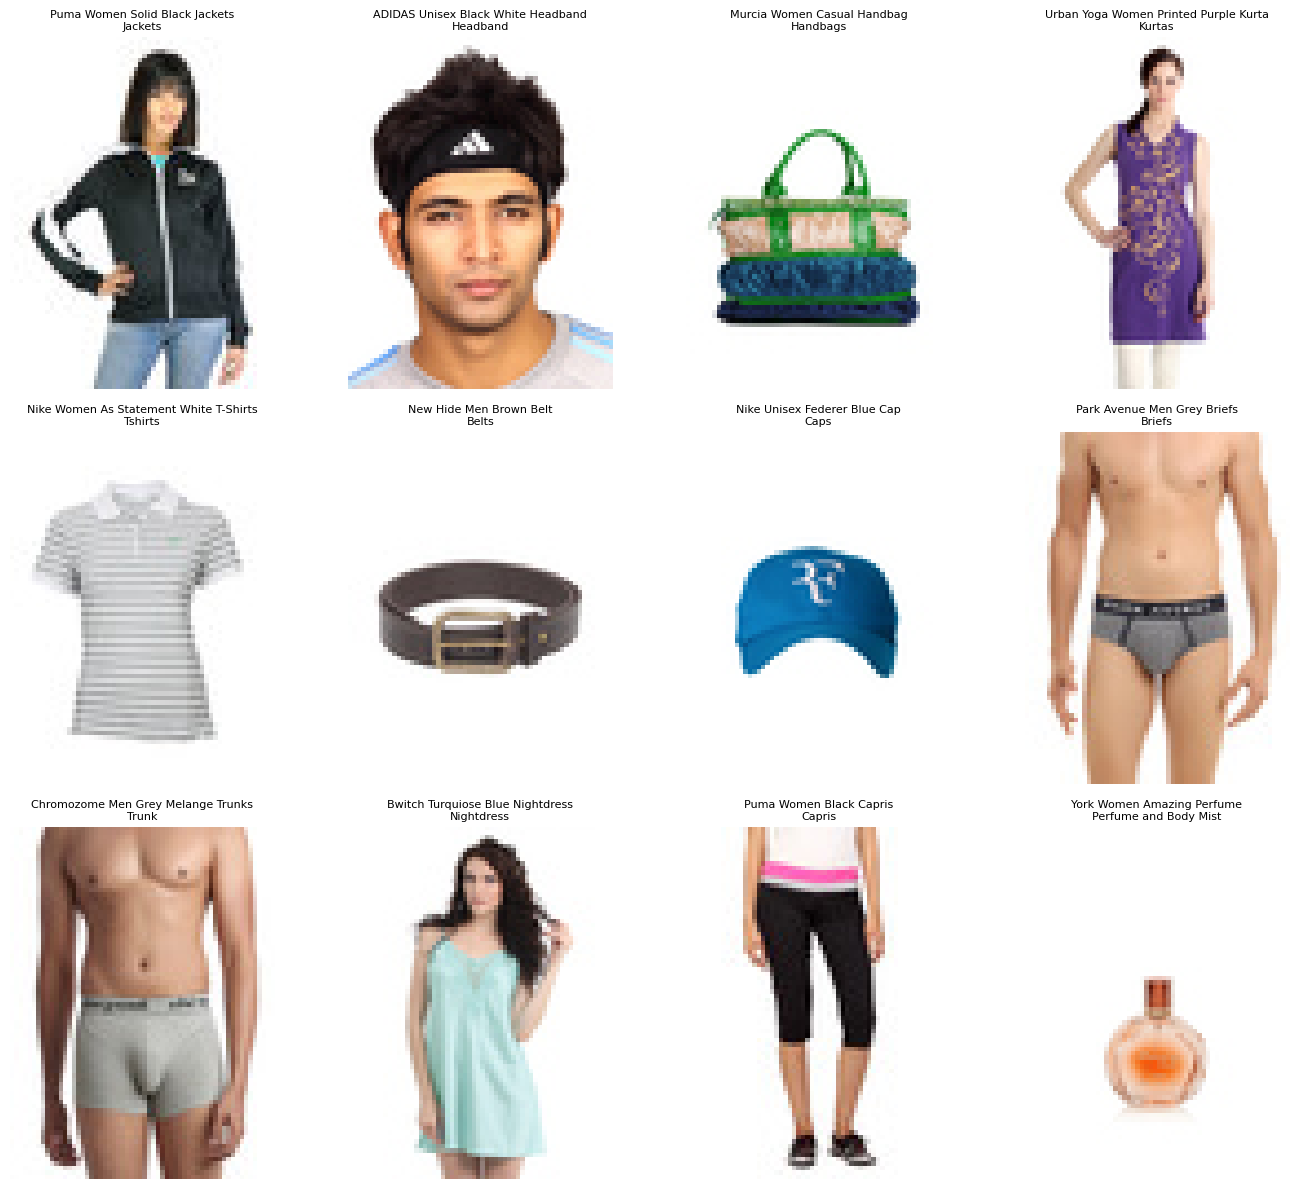

In [6]:
import random
from PIL import Image

sample_df = df.sample(12, random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(14, 12))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    image_file = os.path.join(IMAGE_PATH, f"{row['id']}.jpg")

    if os.path.exists(image_file):
        img = Image.open(image_file).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"{row['productDisplayName']}\n{row['articleType']}",
            fontsize=8
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

# Cell 5 — Dataset Integrity Check

In [7]:
import os
import pandas as pd

# Expected image filenames from metadata
expected_images = set(
    df["id"].astype(str) + ".jpg"
)

# Actual image filenames
actual_images = set(
    file for file in os.listdir(IMAGE_PATH)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
)

# Compare
missing_images = expected_images - actual_images
orphan_images = actual_images - expected_images

print("=" * 50)
print("IMAGE INTEGRITY REPORT")
print("=" * 50)

print(f"Metadata Records: {len(df):,}")
print(f"Actual Images: {len(actual_images):,}")
print(f"Missing Images: {len(missing_images):,}")
print(f"Orphan Images: {len(orphan_images):,}")

print("\nMissing Image Examples:")
print(list(missing_images)[:10])

print("\nOrphan Image Examples:")
print(list(orphan_images)[:10])

IMAGE INTEGRITY REPORT
Metadata Records: 44,424
Actual Images: 44,441
Missing Images: 5
Orphan Images: 22

Missing Image Examples:
['39401.jpg', '12347.jpg', '39410.jpg', '39425.jpg', '39403.jpg']

Orphan Image Examples:
['23101.jpg', '23118.jpg', '4854.jpg', '23116.jpg', '23127.jpg', '23114.jpg', '44065.jpg', '59768.jpg', '23115.jpg', '23109.jpg']


# Cell 6 — Detailed Category Analysis

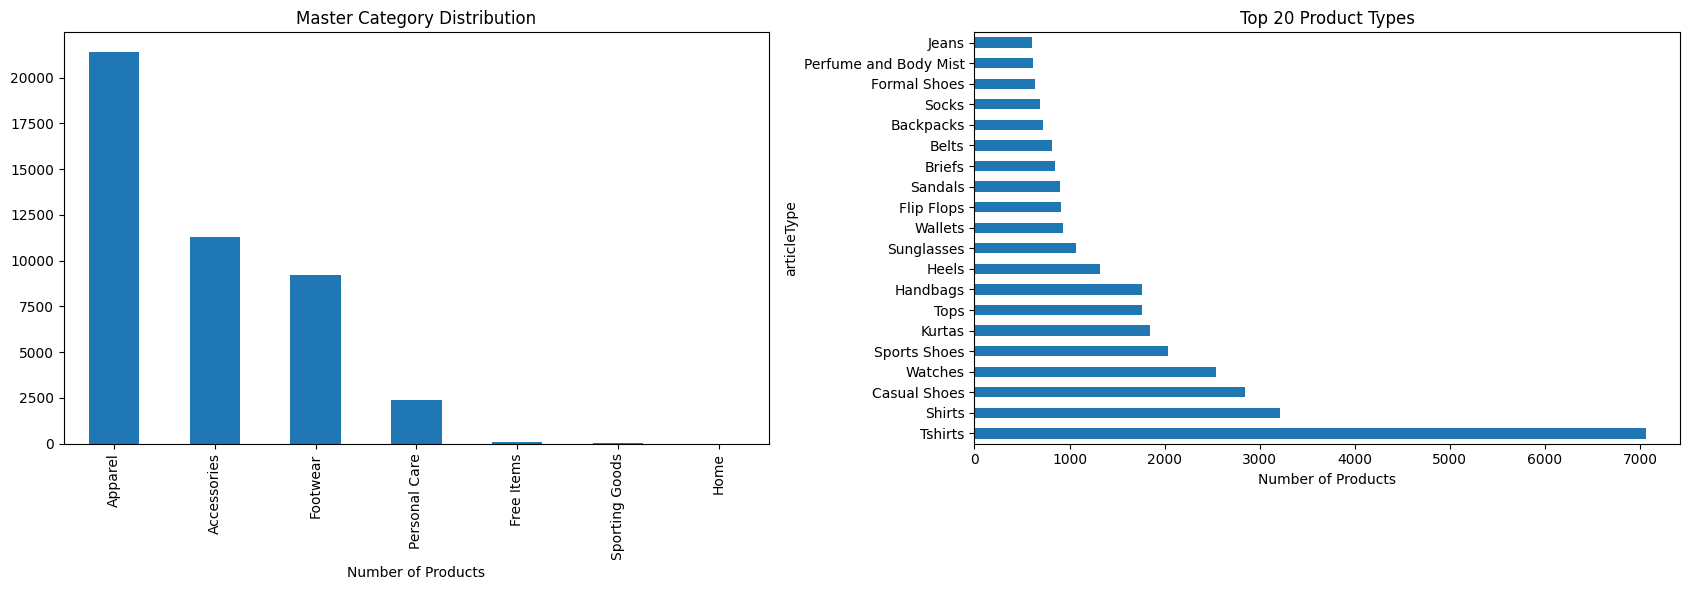

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

df["masterCategory"].value_counts().plot(
    kind="bar",
    ax=axes[0],
    title="Master Category Distribution"
)

df["articleType"].value_counts().head(20).plot(
    kind="barh",
    ax=axes[1],
    title="Top 20 Product Types"
)

axes[0].set_xlabel("Number of Products")
axes[1].set_xlabel("Number of Products")

plt.tight_layout()
plt.show()

# Cell 7 — Metadata Cleaning

In [9]:
# Create a clean working copy
clean_df = df.copy()

# Handle missing values
clean_df["baseColour"] = clean_df["baseColour"].fillna("Unknown")
clean_df["season"] = clean_df["season"].fillna("Unknown")
clean_df["usage"] = clean_df["usage"].fillna("Unknown")

clean_df["productDisplayName"] = (
    clean_df["productDisplayName"].fillna("Unknown Product")
)

# Normalize text columns
text_columns = [
    "gender",
    "masterCategory",
    "subCategory",
    "articleType",
    "baseColour",
    "season",
    "usage",
    "productDisplayName"
]

for col in text_columns:
    clean_df[col] = clean_df[col].astype(str).str.strip()

# Keep records with valid images
valid_image_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(IMAGE_PATH)
    if f.lower().endswith(".jpg")
}

clean_df["id"] = clean_df["id"].astype(str)

clean_df = clean_df[
    clean_df["id"].isin(valid_image_ids)
].copy()

# Remove duplicate IDs if any
clean_df = clean_df.drop_duplicates(subset="id")

clean_df.reset_index(drop=True, inplace=True)

print("Original Records:", len(df))
print("Clean Records:", len(clean_df))
print("Removed Records:", len(df) - len(clean_df))

print("\nRemaining Missing Values:")
display(clean_df.isnull().sum())

Original Records: 44424
Clean Records: 44419
Removed Records: 5

Remaining Missing Values:


id                    0
gender                0
masterCategory        0
subCategory           0
articleType           0
baseColour            0
season                0
year                  1
usage                 0
productDisplayName    0
dtype: int64

# Cell 8 — Image Quality Audit

In [10]:
from PIL import Image
from tqdm.auto import tqdm

image_records = []

for image_id in tqdm(clean_df["id"], desc="Checking Images"):
    image_path = os.path.join(IMAGE_PATH, f"{image_id}.jpg")

    try:
        with Image.open(image_path) as img:
            width, height = img.size

            image_records.append({
                "id": image_id,
                "width": width,
                "height": height,
                "format": img.format,
                "mode": img.mode,
                "valid": True
            })

    except Exception as e:
        image_records.append({
            "id": image_id,
            "width": None,
            "height": None,
            "format": None,
            "mode": None,
            "valid": False
        })

image_quality_df = pd.DataFrame(image_records)

print("Image Quality Report")
print("=" * 40)
print("Total Checked:", len(image_quality_df))
print("Valid Images:", image_quality_df["valid"].sum())
print("Corrupted Images:", (~image_quality_df["valid"]).sum())

display(image_quality_df.head())

Checking Images:   0%|          | 0/44419 [00:00<?, ?it/s]

Image Quality Report
Total Checked: 44419
Valid Images: 44419
Corrupted Images: 0


,id,width,height,format,mode,valid
0,15970,60,80,JPEG,RGB,True
1,39386,60,80,JPEG,RGB,True
2,59263,60,80,JPEG,L,True
3,21379,60,80,JPEG,RGB,True
4,53759,60,80,JPEG,RGB,True


# Cell 9 — Image Dimensions Distribution

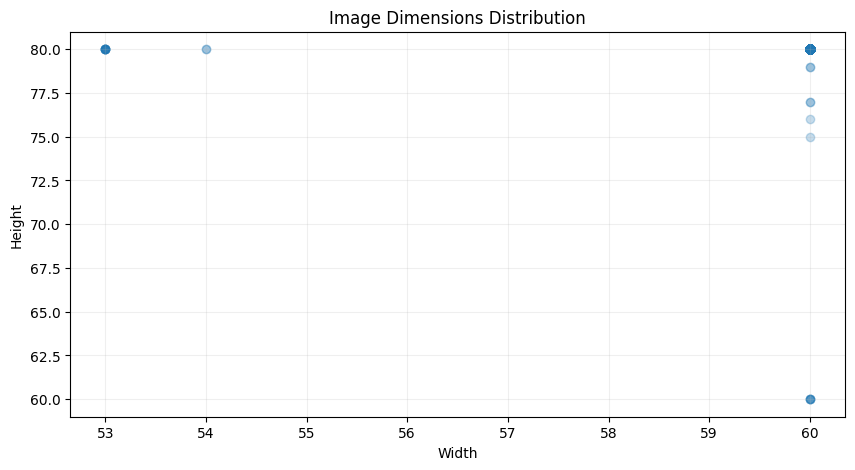


Dimension Statistics:


,width,height
count,44419.000000,44419.000000
mean,59.998154,79.997366
std,0.112468,0.215391
min,53.000000,60.000000
25%,60.000000,80.000000
50%,60.000000,80.000000
75%,60.000000,80.000000
max,60.000000,80.000000


In [11]:
valid_dimensions = image_quality_df[
    image_quality_df["valid"]
].copy()

plt.figure(figsize=(10, 5))

plt.scatter(
    valid_dimensions["width"],
    valid_dimensions["height"],
    alpha=0.25
)

plt.title("Image Dimensions Distribution")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid(alpha=0.2)
plt.show()

print("\nDimension Statistics:")
display(valid_dimensions[["width", "height"]].describe())

# Cell 10 — Visualize Image Quality

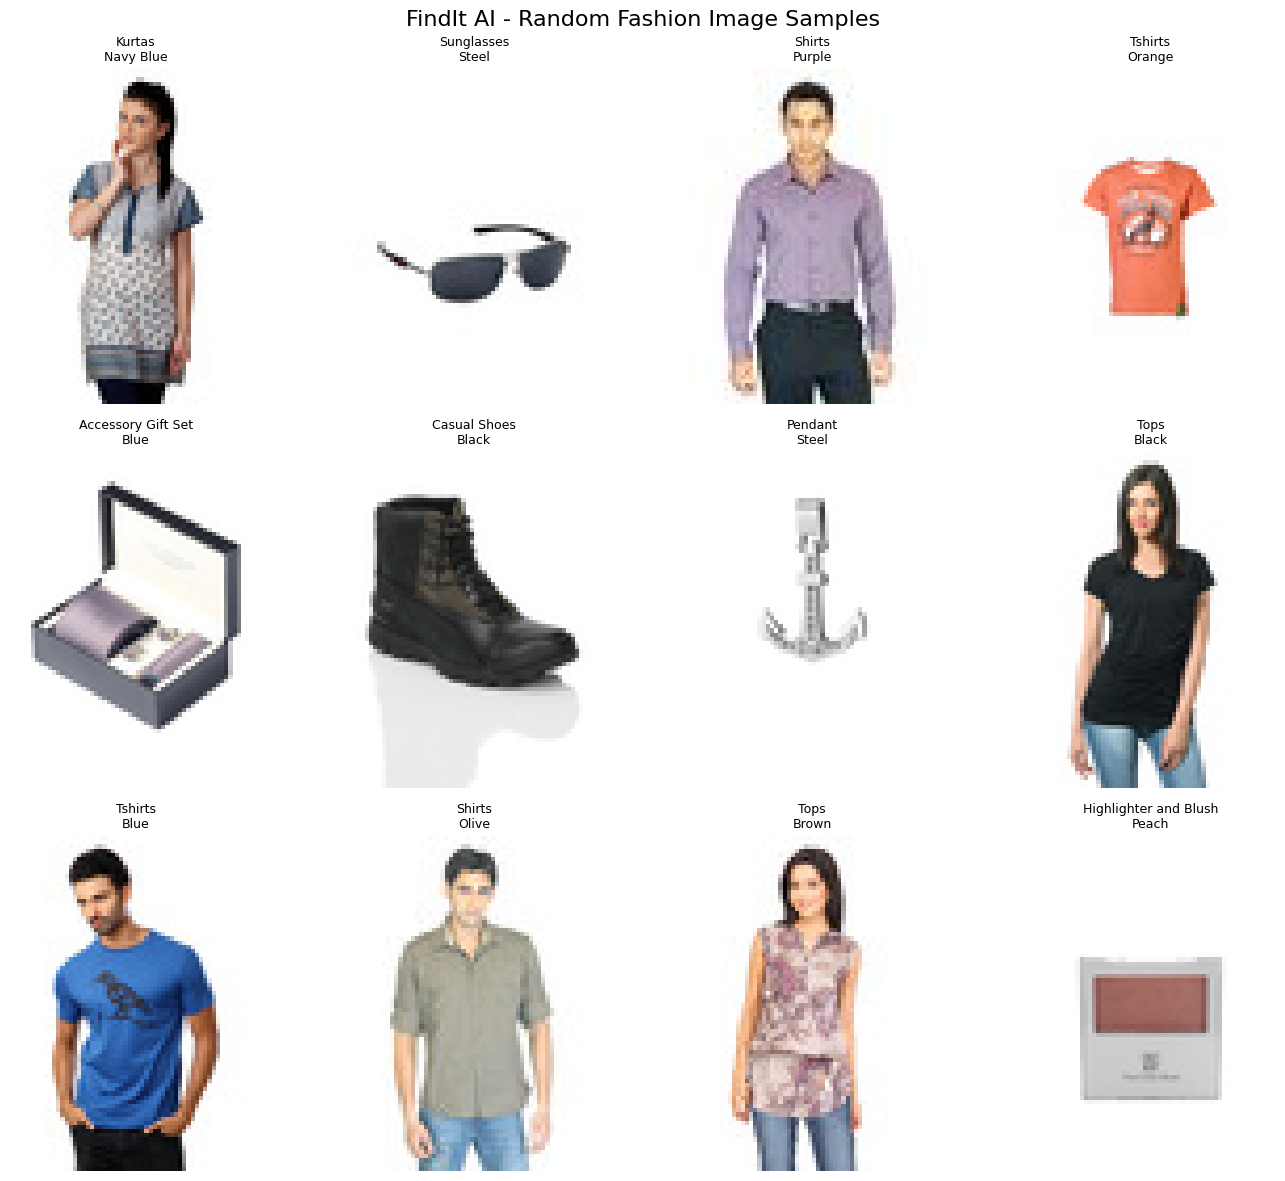

In [12]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

sample_ids = random.sample(clean_df["id"].tolist(), 12)

fig, axes = plt.subplots(3, 4, figsize=(14, 12))
axes = axes.flatten()

for ax, image_id in zip(axes, sample_ids):
    image_path = os.path.join(IMAGE_PATH, f"{image_id}.jpg")

    image = Image.open(image_path).convert("RGB")

    row = clean_df.loc[clean_df["id"] == image_id].iloc[0]

    ax.imshow(image)
    ax.set_title(
        f"{row['articleType']}\n{row['baseColour']}",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("FindIt AI - Random Fashion Image Samples", fontsize=16)
plt.tight_layout()
plt.show()

# Cell 11 — Verify Image & Metadata Mapping

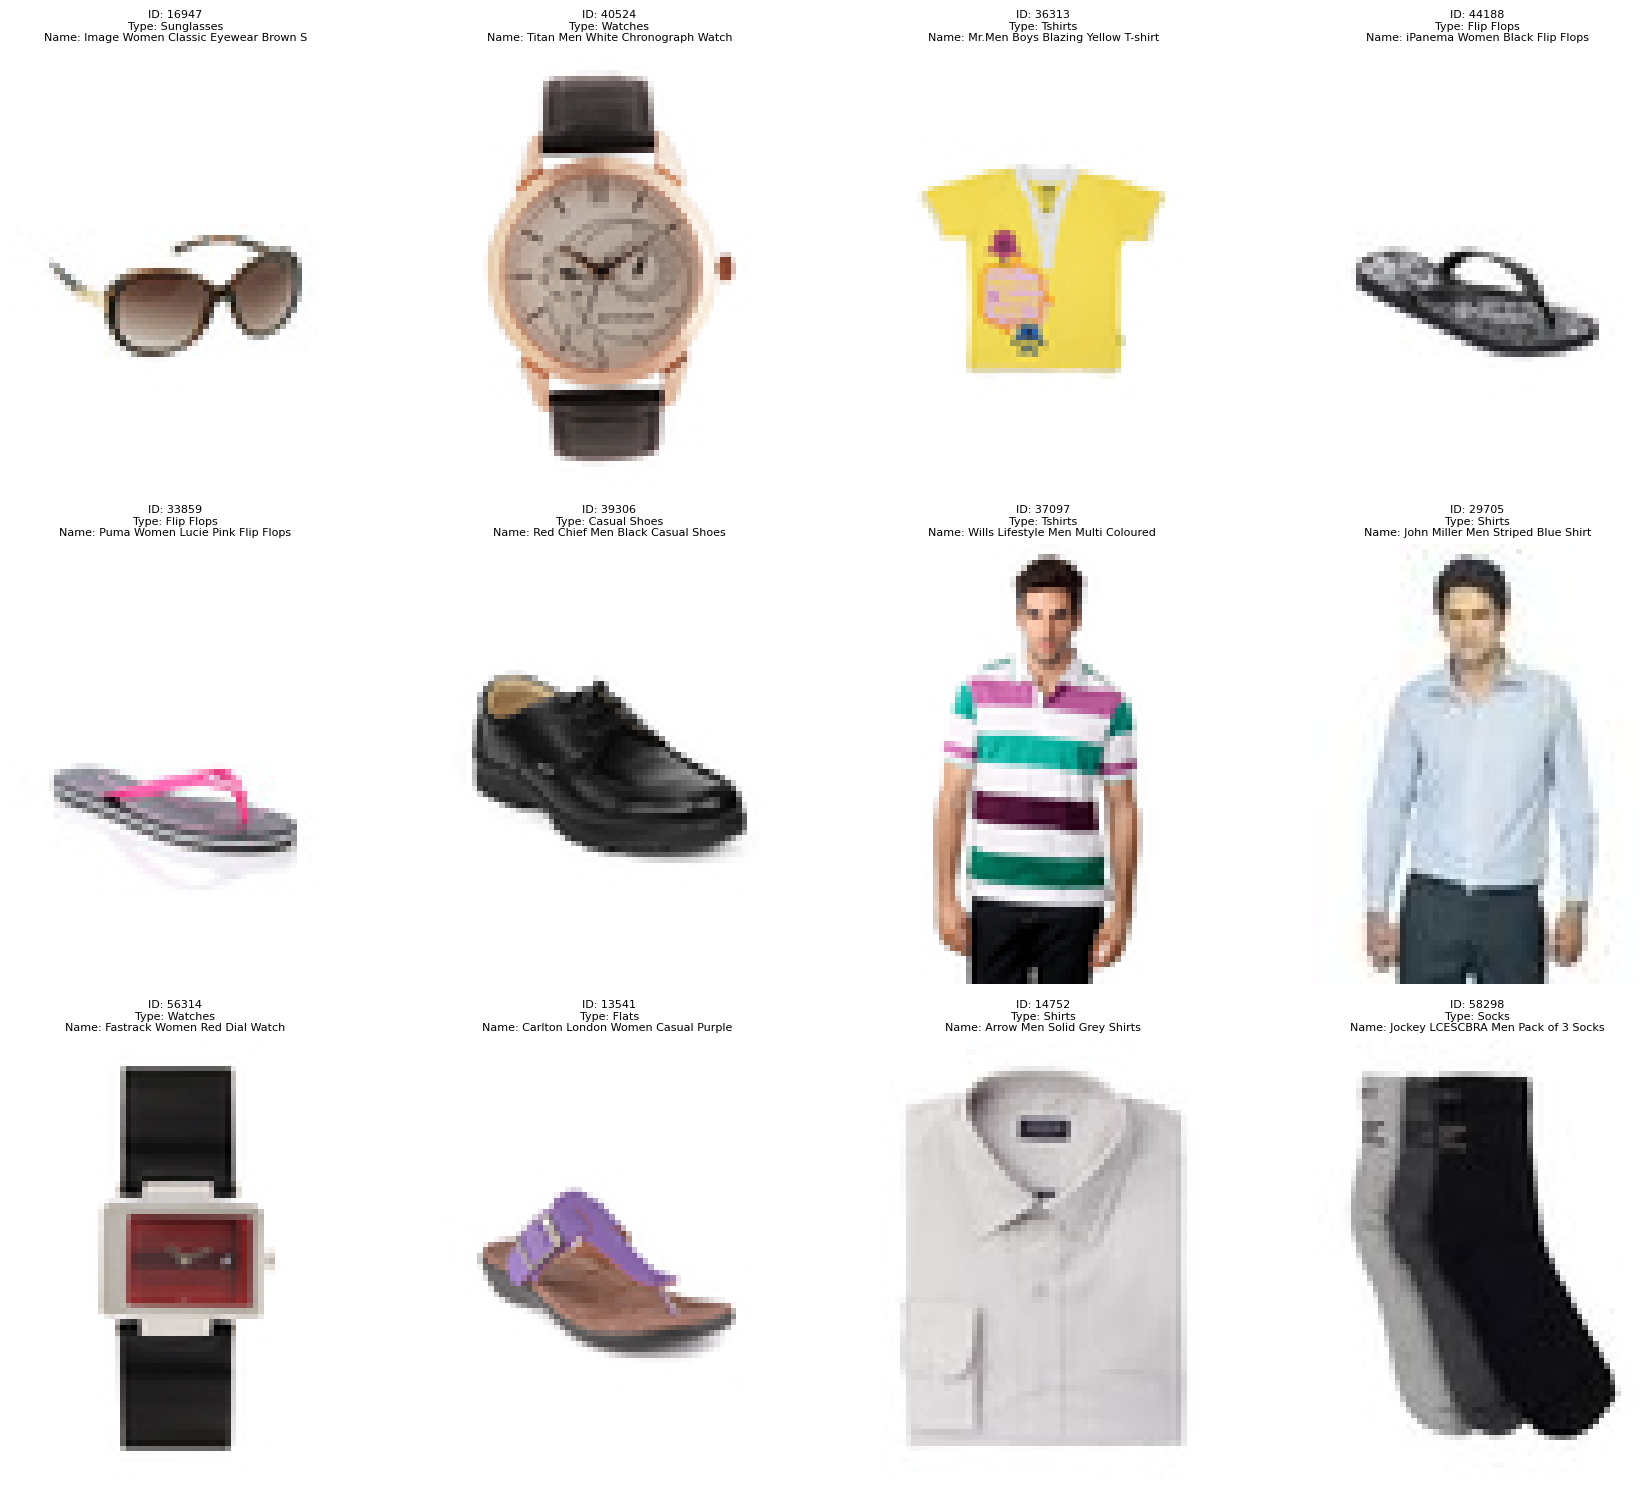

,id,image_path,articleType,productDisplayName,gender,baseColour
0,16947,/kaggle/input/datasets/paramaggarwal/fashion-p...,Sunglasses,Image Women Classic Eyewear Brown Sunglasses,Women,Brown
1,40524,/kaggle/input/datasets/paramaggarwal/fashion-p...,Watches,Titan Men White Chronograph Watch,Men,White
2,36313,/kaggle/input/datasets/paramaggarwal/fashion-p...,Tshirts,Mr.Men Boys Blazing Yellow T-shirt,Boys,Yellow
3,44188,/kaggle/input/datasets/paramaggarwal/fashion-p...,Flip Flops,iPanema Women Black Flip Flops,Women,Black
4,33859,/kaggle/input/datasets/paramaggarwal/fashion-p...,Flip Flops,Puma Women Lucie Pink Flip Flops,Women,Pink
5,39306,/kaggle/input/datasets/paramaggarwal/fashion-p...,Casual Shoes,Red Chief Men Black Casual Shoes,Men,Black
6,37097,/kaggle/input/datasets/paramaggarwal/fashion-p...,Tshirts,Wills Lifestyle Men Multi Coloured Polo T-shirt,Men,Green
7,29705,/kaggle/input/datasets/paramaggarwal/fashion-p...,Shirts,John Miller Men Striped Blue Shirt,Men,Blue
8,56314,/kaggle/input/datasets/paramaggarwal/fashion-p...,Watches,Fastrack Women Red Dial Watch,Women,Red
9,13541,/kaggle/input/datasets/paramaggarwal/fashion-p...,Flats,Carlton London Women Casual Purple Sandals,Women,Purple


In [13]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Fixed sample for reproducibility
sample_df = clean_df.sample(12, random_state=42).reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(18, 15))
axes = axes.flatten()

audit_records = []

for idx, (_, row) in enumerate(sample_df.iterrows()):

    image_id = str(row["id"])
    image_path = os.path.join(IMAGE_PATH, f"{image_id}.jpg")

    image = Image.open(image_path).convert("RGB")

    axes[idx].imshow(image)
    axes[idx].set_title(
        f"ID: {image_id}\n"
        f"Type: {row['articleType']}\n"
        f"Name: {row['productDisplayName'][:35]}",
        fontsize=8
    )
    axes[idx].axis("off")

    audit_records.append({
        "id": image_id,
        "image_path": image_path,
        "articleType": row["articleType"],
        "productDisplayName": row["productDisplayName"],
        "gender": row["gender"],
        "baseColour": row["baseColour"]
    })

plt.tight_layout()
plt.show()

mapping_audit = pd.DataFrame(audit_records)
display(mapping_audit)

# Cell 12 — Environment & GPU Check

In [14]:
import torch
import platform
import os

print("=" * 45)
print("FindIt AI - Runtime Environment")
print("=" * 45)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)

print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

print("\nCPU Cores:", os.cpu_count())

print("\nCUDA Version:", torch.version.cuda)

print("=" * 45)

FindIt AI - Runtime Environment
Python: 3.13.16
PyTorch: 2.11.0+cu130

GPU Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB

CPU Cores: 4

CUDA Version: 13.0


# Cell 13 — Check Required Libraries

In [15]:
import importlib.util

packages = {
    "transformers": "transformers",
    "open_clip": "open_clip_torch",
    "faiss": "faiss-cpu",
    "sklearn": "scikit-learn",
    "tqdm": "tqdm"
}

print("FindIt AI - Dependency Check")
print("=" * 40)

for package, install_name in packages.items():
    installed = importlib.util.find_spec(package) is not None
    status = "Installed" if installed else "Not Installed"
    print(f"{package:<15} {status}")

print("=" * 40)

FindIt AI - Dependency Check
transformers    Installed
open_clip       Not Installed
faiss           Not Installed
sklearn         Installed
tqdm            Installed


# Cell 14 — Install FAISS

In [16]:
%pip install -q faiss-cpu --no-deps

Note: you may need to restart the kernel to use updated packages.


# Cell 15 — Verify FAISS

In [17]:
import faiss
import transformers
import torch

print("FAISS Version:", faiss.__version__)
print("Transformers Version:", transformers.__version__)
print("PyTorch Version:", torch.__version__)

print("\nAll core libraries are ready!")

FAISS Version: 1.16.0
Transformers Version: 5.20.2
PyTorch Version: 2.11.0+cu130

All core libraries are ready!


# Cell 16 — Load CLIP Model

In [18]:
import torch
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"

device = torch.device("cpu")

print("Loading CLIP Model...")

processor = CLIPProcessor.from_pretrained(MODEL_NAME)

model = CLIPModel.from_pretrained(MODEL_NAME)
model = model.to(device)
model.eval()

print("\nCLIP Model Loaded Successfully!")
print("Model:", MODEL_NAME)
print("Device:", device)
print("Embedding Dimension:", model.config.projection_dim)

Loading CLIP Model...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

... (2 outputs left out)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


CLIP Model Loaded Successfully!
Model: openai/clip-vit-base-patch32
Device: cpu
Embedding Dimension: 512


# Cell 17 — Restore Clean Dataset

In [19]:
import os
import pandas as pd
import numpy as np
from PIL import Image

BASE_PATH = "/kaggle/input/datasets/paramaggarwal/fashion-product-images-small"
IMAGE_PATH = os.path.join(BASE_PATH, "images")
CSV_PATH = os.path.join(BASE_PATH, "styles.csv")

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

# Restore image IDs
valid_image_ids = {
    os.path.splitext(f)[0]
    for f in os.listdir(IMAGE_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

clean_df = df.copy()

# Clean metadata
for col in ["gender", "masterCategory", "subCategory",
            "articleType", "baseColour", "season",
            "usage", "productDisplayName"]:
    clean_df[col] = clean_df[col].fillna("Unknown").astype(str).str.strip()

clean_df["productDisplayName"] = clean_df["productDisplayName"].replace(
    "", "Unknown Product"
)

clean_df["id"] = clean_df["id"].astype(str)

clean_df = clean_df[
    clean_df["id"].isin(valid_image_ids)
].drop_duplicates(subset="id").reset_index(drop=True)

print("Dataset Restored Successfully!")
print("Clean Records:", len(clean_df))
print("Missing Values:", clean_df.isnull().sum().sum())

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Dataset Restored Successfully!
Clean Records: 44419
Missing Values: 1


In [20]:
import torch
import numpy as np
from PIL import Image
import os

# Select 8 sample images
sample_df = clean_df.sample(8, random_state=42).reset_index(drop=True)

sample_images = []

for image_id in sample_df["id"]:
    image_path = os.path.join(IMAGE_PATH, f"{image_id}.jpg")

    image = Image.open(image_path).convert("RGB")
    sample_images.append(image)

# Process images
inputs = processor(
    images=sample_images,
    return_tensors="pt"
)

# Extract image features directly
with torch.no_grad():

    vision_outputs = model.vision_model(
        pixel_values=inputs["pixel_values"].to(device),
        return_dict=True
    )

    pooled_output = vision_outputs.pooler_output

    image_features = model.visual_projection(pooled_output)

# Convert to NumPy
embeddings = image_features.cpu().numpy()

# Normalize embeddings
embeddings = embeddings / np.linalg.norm(
    embeddings, axis=1, keepdims=True
)

print("Embedding Test Results")
print("=" * 40)

print("Number of Images:", len(sample_images))
print("Embedding Shape:", embeddings.shape)
print("Embedding Dimension:", embeddings.shape[1])
print("All Finite:", np.isfinite(embeddings).all())

print("Normalized:", np.allclose(
    np.linalg.norm(embeddings, axis=1),
    1.0,
    atol=1e-5
))

print("=" * 40)

Embedding Test Results
Number of Images: 8
Embedding Shape: (8, 512)
Embedding Dimension: 512
All Finite: True
Normalized: True


# Cell 18 — Prepare Embedding Pipeline

In [21]:
import os
import gc
import json
import numpy as np
import torch

from tqdm.auto import tqdm
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Configuration
BATCH_SIZE = 32
EMBEDDING_DIM = 512

OUTPUT_DIR = "/kaggle/working/findit_artifacts"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Reset index to preserve consistent ordering
clean_df = clean_df.reset_index(drop=True)

# Build image paths
image_paths = [
    os.path.join(IMAGE_PATH, f"{image_id}.jpg")
    for image_id in clean_df["id"]
]

# Verify paths
missing_paths = [p for p in image_paths if not os.path.exists(p)]

print("Pipeline Configuration")
print("=" * 40)
print("Total Images:", len(image_paths))
print("Batch Size:", BATCH_SIZE)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Output Directory:", OUTPUT_DIR)
print("Missing Paths:", len(missing_paths))
print("=" * 40)

assert len(missing_paths) == 0, "Some image paths are missing!"

Pipeline Configuration
Total Images: 44419
Batch Size: 32
Embedding Dimension: 512
Output Directory: /kaggle/working/findit_artifacts
Missing Paths: 0


# Cell 19 — Create Image Dataset & DataLoader

In [22]:
from torch.utils.data import Dataset, DataLoader

class FashionImageDataset(Dataset):

    def __init__(self, image_paths):
        self.image_paths = image_paths

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("RGB")
        return idx, image


def collate_fn(batch):

    indices, images = zip(*batch)

    inputs = processor(
        images=list(images),
        return_tensors="pt"
    )

    return torch.tensor(indices), inputs["pixel_values"]


# Create Dataset
image_dataset = FashionImageDataset(image_paths)

# Create DataLoader
image_loader = DataLoader(
    image_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

print("Dataset & DataLoader Created!")
print("=" * 40)
print("Dataset Size:", len(image_dataset))
print("Number of Batches:", len(image_loader))
print("Batch Size:", BATCH_SIZE)

# Test first batch
batch_indices, batch_pixels = next(iter(image_loader))

print("\nFirst Batch Test")
print("Indices Shape:", batch_indices.shape)
print("Pixels Shape:", batch_pixels.shape)
print("Pixel Data Type:", batch_pixels.dtype)

print("=" * 40)

Dataset & DataLoader Created!
Dataset Size: 44419
Number of Batches: 1389
Batch Size: 32

First Batch Test
Indices Shape: torch.Size([32])
Pixels Shape: torch.Size([32, 3, 224, 224])
Pixel Data Type: torch.float32


# Cell 20 — Initialize Embedding Storage

In [23]:
import numpy as np
import os
import json
import gc

EMBEDDINGS_PATH = os.path.join(OUTPUT_DIR, "image_embeddings.dat")
PROGRESS_PATH = os.path.join(OUTPUT_DIR, "progress.json")

TOTAL_IMAGES = len(clean_df)

# Create disk-based embedding storage
embeddings_map = np.memmap(
    EMBEDDINGS_PATH,
    dtype="float32",
    mode="w+",
    shape=(TOTAL_IMAGES, EMBEDDING_DIM)
)

# Initialize progress
progress = {
    "completed_batches": [],
    "total_images": TOTAL_IMAGES,
    "batch_size": BATCH_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "model": MODEL_NAME
}

with open(PROGRESS_PATH, "w") as f:
    json.dump(progress, f, indent=4)

print("Embedding Storage Initialized!")
print("=" * 40)
print("Storage Shape:", embeddings_map.shape)
print("Storage Size:", round(
    TOTAL_IMAGES * EMBEDDING_DIM * 4 / (1024**2), 2
), "MB")
print("Storage Path:", EMBEDDINGS_PATH)
print("=" * 40)

Embedding Storage Initialized!
Storage Shape: (44419, 512)
Storage Size: 86.76 MB
Storage Path: /kaggle/working/findit_artifacts/image_embeddings.dat


# Cell 21 — Extract Image Embeddings

In [24]:
import time
import torch
import json
import numpy as np
from tqdm.auto import tqdm

CHECKPOINT_INTERVAL = 25

completed_batches = set()
embeddings_map = np.memmap(
    EMBEDDINGS_PATH,
    dtype="float32",
    mode="r+",
    shape=(TOTAL_IMAGES, EMBEDDING_DIM)
)

start_time = time.time()

model.eval()

for batch_idx, (indices, pixel_values) in enumerate(
    tqdm(image_loader, desc="Extracting CLIP Embeddings")
):

    if batch_idx in completed_batches:
        continue

    pixel_values = pixel_values.to(device)

    with torch.inference_mode():
        vision_outputs = model.vision_model(
            pixel_values=pixel_values,
            return_dict=True
        )

        pooled_output = vision_outputs.pooler_output
        features = model.visual_projection(pooled_output)

        features = features / features.norm(
            p=2, dim=-1, keepdim=True
        )

    batch_embeddings = features.cpu().numpy()

    embeddings_map[indices.numpy()] = batch_embeddings

    del pixel_values, vision_outputs, pooled_output
    del features, batch_embeddings

    # Save checkpoint every 25 batches
    if (batch_idx + 1) % CHECKPOINT_INTERVAL == 0:

        embeddings_map.flush()

        progress["completed_batches"] = list(
            range(batch_idx + 1)
        )

        with open(PROGRESS_PATH, "w") as f:
            json.dump(progress, f, indent=4)

        gc.collect()

# Final save
embeddings_map.flush()

progress["completed_batches"] = list(range(len(image_loader)))
progress["completed"] = True

with open(PROGRESS_PATH, "w") as f:
    json.dump(progress, f, indent=4)

elapsed_time = time.time() - start_time

print("\nEmbedding Extraction Completed!")
print("=" * 45)
print("Total Images:", TOTAL_IMAGES)
print("Total Batches:", len(image_loader))
print("Embedding Dimension:", EMBEDDING_DIM)
print("Execution Time:", round(elapsed_time / 60, 2), "minutes")
print("Embeddings Saved:", EMBEDDINGS_PATH)
print("=" * 45)

Extracting CLIP Embeddings:   0%|          | 0/1389 [00:00<?, ?it/s]


Embedding Extraction Completed!
Total Images: 44419
Total Batches: 1389
Embedding Dimension: 512
Execution Time: 40.49 minutes
Embeddings Saved: /kaggle/working/findit_artifacts/image_embeddings.dat


# Cell 22 — Validate Extracted Embeddings

In [25]:
import numpy as np
import os

embeddings_map = np.memmap(
    EMBEDDINGS_PATH,
    dtype="float32",
    mode="r",
    shape=(TOTAL_IMAGES, EMBEDDING_DIM)
)

# Inspect embeddings
sample_embeddings = np.array(embeddings_map[:1000])

norms = np.linalg.norm(sample_embeddings, axis=1)

print("Embedding Validation Report")
print("=" * 45)

print("Total Embeddings:", embeddings_map.shape[0])
print("Embedding Dimensions:", embeddings_map.shape[1])

print("All Finite:",
      np.isfinite(sample_embeddings).all())

print("All Normalized:",
      np.allclose(norms, 1.0, atol=1e-4))

print("Minimum Norm:", round(norms.min(), 6))
print("Maximum Norm:", round(norms.max(), 6))

print("Storage Size:",
      round(os.path.getsize(EMBEDDINGS_PATH) / (1024**2), 2),
      "MB")

print("=" * 45)

Embedding Validation Report
Total Embeddings: 44419
Embedding Dimensions: 512
All Finite: True
All Normalized: True
Minimum Norm: 1.0
Maximum Norm: 1.0
Storage Size: 86.76 MB


# Cell 23 — Save Current Session

In [26]:
import os
import json
import pickle
import random
import shutil
import joblib
import torch
import numpy as np
import pandas as pd

from datetime import datetime

# ==========================================
# 1. Backup Configuration
# ==========================================

BACKUP_ROOT = "/kaggle/working/session_backup"

os.makedirs(BACKUP_ROOT, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

SESSION_DIR = os.path.join(
    BACKUP_ROOT,
    f"FindIt_AI_Backup_{timestamp}"
)

os.makedirs(SESSION_DIR, exist_ok=False)

print("Starting FindIt AI Session Backup...")
print("=" * 55)

saved_files = []
failed_files = []

# ==========================================
# 2. Helper Function
# ==========================================

def save_safely(name, save_function):

    try:
        save_function()
        saved_files.append(name)
        print(f"[SAVED] {name}")

    except Exception as e:
        failed_files.append({
            "file": name,
            "error": str(e)
        })

        print(f"[FAILED] {name}: {e}")


# ==========================================
# 3. Save Important Variables
# ==========================================

important_variables = {
    "clean_df": clean_df if "clean_df" in globals() else None,
    "df": df if "df" in globals() else None,
    "image_paths": image_paths if "image_paths" in globals() else None,
    "MODEL_NAME": MODEL_NAME if "MODEL_NAME" in globals() else None,
    "BASE_PATH": BASE_PATH if "BASE_PATH" in globals() else None,
    "IMAGE_PATH": IMAGE_PATH if "IMAGE_PATH" in globals() else None,
    "BATCH_SIZE": BATCH_SIZE if "BATCH_SIZE" in globals() else None,
    "EMBEDDING_DIM": EMBEDDING_DIM if "EMBEDDING_DIM" in globals() else None,
    "TOTAL_IMAGES": TOTAL_IMAGES if "TOTAL_IMAGES" in globals() else None,
}

save_safely(
    "important_variables.joblib",
    lambda: joblib.dump(
        important_variables,
        os.path.join(SESSION_DIR, "important_variables.joblib")
    )
)


# ==========================================
# 4. Save Clean Dataset Separately
# ==========================================

if "clean_df" in globals():

    save_safely(
        "clean_metadata.pkl",
        lambda: clean_df.to_pickle(
            os.path.join(SESSION_DIR, "clean_metadata.pkl")
        )
    )


# ==========================================
# 5. Save CLIP Model & Processor
# ==========================================

if "model" in globals():

    save_safely(
        "CLIP Model",
        lambda: model.save_pretrained(
            os.path.join(SESSION_DIR, "clip_model"),
            safe_serialization=True
        )
    )

if "processor" in globals():

    save_safely(
        "CLIP Processor",
        lambda: processor.save_pretrained(
            os.path.join(SESSION_DIR, "clip_processor")
        )
    )


# ==========================================
# 6. Save Embeddings
# ==========================================

embedding_source = os.path.join(
    OUTPUT_DIR,
    "image_embeddings.dat"
)

if os.path.exists(embedding_source):

    if "embeddings_map" in globals():
        embeddings_map.flush()

    save_safely(
        "image_embeddings.dat",
        lambda: shutil.copy2(
            embedding_source,
            os.path.join(SESSION_DIR, "image_embeddings.dat")
        )
    )


# ==========================================
# 7. Save Extraction Progress
# ==========================================

progress_source = os.path.join(
    OUTPUT_DIR,
    "progress.json"
)

if os.path.exists(progress_source):

    save_safely(
        "progress.json",
        lambda: shutil.copy2(
            progress_source,
            os.path.join(SESSION_DIR, "progress.json")
        )
    )


# ==========================================
# 8. Save Random States
# ==========================================

random_states = {
    "python_random": random.getstate(),
    "numpy_random": np.random.get_state(),
    "torch_random": torch.get_rng_state(),
    "torch_cuda_random": (
        torch.cuda.get_rng_state_all()
        if torch.cuda.is_available()
        else None
    )
}

save_safely(
    "random_states.pkl",
    lambda: pickle.dump(
        random_states,
        open(os.path.join(SESSION_DIR, "random_states.pkl"), "wb")
    )
)


# ==========================================
# 9. Save Configuration
# ==========================================

configuration = {
    "project": "FindIt AI",
    "model": MODEL_NAME,
    "embedding_dimension": EMBEDDING_DIM,
    "batch_size": BATCH_SIZE,
    "total_images": TOTAL_IMAGES,
    "device": str(device),
    "python_version": __import__("platform").python_version(),
    "pytorch_version": torch.__version__,
    "transformers_version": __import__("transformers").__version__,
    "created_at": timestamp
}

save_safely(
    "configuration.json",
    lambda: json.dump(
        configuration,
        open(os.path.join(SESSION_DIR, "configuration.json"), "w"),
        indent=4
    )
)


# ==========================================
# 10. Save Manifest
# ==========================================

manifest = {
    "backup_name": os.path.basename(SESSION_DIR),
    "created_at": timestamp,
    "saved_files": saved_files,
    "failed_files": failed_files,
    "session_directory": SESSION_DIR
}

with open(
    os.path.join(SESSION_DIR, "manifest.json"),
    "w"
) as f:
    json.dump(manifest, f, indent=4)

print("\nBackup Process Finished!")
print("=" * 55)
print("Backup Directory:", SESSION_DIR)
print("Successfully Saved:", len(saved_files))
print("Failed:", len(failed_files))

for item in failed_files:
    print("WARNING:", item)

print("=" * 55)

Starting FindIt AI Session Backup...
[SAVED] important_variables.joblib
[SAVED] clean_metadata.pkl


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[SAVED] CLIP Model
[SAVED] CLIP Processor
[SAVED] image_embeddings.dat
[SAVED] progress.json
[SAVED] random_states.pkl
[SAVED] configuration.json

Backup Process Finished!
Backup Directory: /kaggle/working/session_backup/FindIt_AI_Backup_20261117_164454
Successfully Saved: 8
Failed: 0


# Cell 24 — Save Files to Kaggle Output

In [27]:
import os
import json

print("FindIt AI - Backup Verification")
print("=" * 55)

backup_files = []

for root, dirs, files in os.walk(SESSION_DIR):

    for file in files:

        file_path = os.path.join(root, file)

        file_size = os.path.getsize(file_path)

        relative_path = os.path.relpath(
            file_path,
            SESSION_DIR
        )

        backup_files.append({
            "file": relative_path,
            "size_mb": round(file_size / (1024**2), 3)
        })

for item in backup_files:

    print(
        f"[OK] {item['file']:<45} "
        f"{item['size_mb']} MB"
    )

total_size = sum(
    item["size_mb"] for item in backup_files
)

print("\nTotal Files:", len(backup_files))
print("Total Backup Size:", round(total_size, 2), "MB")

print("\nBackup Location:")
print(SESSION_DIR)

print("=" * 55)

FindIt AI - Backup Verification
[OK] image_embeddings.dat                          86.756 MB
[OK] progress.json                                 0.018 MB
[OK] clean_metadata.pkl                            3.385 MB
[OK] manifest.json                                 0.0 MB
[OK] configuration.json                            0.0 MB
[OK] important_variables.joblib                    9.737 MB
[OK] random_states.pkl                             0.012 MB
[OK] clip_model/config.json                        0.002 MB
[OK] clip_model/model.safetensors                  577.122 MB
[OK] clip_processor/tokenizer_config.json          0.0 MB
[OK] clip_processor/processor_config.json          0.001 MB
[OK] clip_processor/tokenizer.json                 3.473 MB

Total Files: 12
Total Backup Size: 680.51 MB

Backup Location:
/kaggle/working/session_backup/FindIt_AI_Backup_20261117_164454


# Cell 25 — Session Status

In [28]:
import os
import json

print("FindIt AI - Session Status")
print("=" * 55)

backup_exists = os.path.exists(BACKUP_ROOT)

print("Backup Exists:", backup_exists)

if backup_exists:

    available_backups = sorted([
        d for d in os.listdir(BACKUP_ROOT)
        if os.path.isdir(os.path.join(BACKUP_ROOT, d))
    ])

    if available_backups:

        latest_backup = available_backups[-1]

        latest_path = os.path.join(
            BACKUP_ROOT,
            latest_backup
        )

        print("\nLatest Backup:", latest_backup)

        manifest_path = os.path.join(
            latest_path,
            "manifest.json"
        )

        if os.path.exists(manifest_path):

            with open(manifest_path) as f:
                manifest = json.load(f)

            print("\nSuccessfully Saved:")

            for file in manifest["saved_files"]:
                print("[OK]", file)

            print("\nFailed Files:")

            if manifest["failed_files"]:
                for item in manifest["failed_files"]:
                    print("[FAILED]", item)
            else:
                print("None")

        print("\nBackup Size:")

        total_bytes = sum(
            os.path.getsize(os.path.join(root, file))
            for root, _, files in os.walk(latest_path)
            for file in files
        )

        print(round(total_bytes / (1024**2), 2), "MB")

    else:
        print("No backup folders found.")

else:
    print("No previous backup found.")

print("\nRESTORE INSTRUCTIONS")
print("-" * 55)
print("1. Save a Kaggle Notebook Version with its output.")
print("2. Reopen the notebook later.")
print("3. Attach the saved notebook output if necessary.")
print("4. Configure BACKUP_SOURCE in Cell 26.")
print("5. Run the Restore Session Cell.")

print("=" * 55)

FindIt AI - Session Status
Backup Exists: True

Latest Backup: FindIt_AI_Backup_20261117_164454

Successfully Saved:
[OK] important_variables.joblib
[OK] clean_metadata.pkl
[OK] CLIP Model
[OK] CLIP Processor
[OK] image_embeddings.dat
[OK] progress.json
[OK] random_states.pkl
[OK] configuration.json

Failed Files:
None

Backup Size:
680.51 MB

RESTORE INSTRUCTIONS
-------------------------------------------------------
1. Save a Kaggle Notebook Version with its output.
2. Reopen the notebook later.
3. Attach the saved notebook output if necessary.
4. Configure BACKUP_SOURCE in Cell 26.
5. Run the Restore Session Cell.


# Cell 27 — Check Current Session

In [29]:
import os
import numpy as np
import faiss
import pandas as pd

print(" FindIt AI - FAISS Preparation")
print("=" * 50)

required_variables = [
    "clean_df",
    "embeddings_map",
    "model",
    "processor",
    "device",
    "OUTPUT_DIR"
]

for variable in required_variables:
    exists = variable in globals()
    print(f"{'✅' if exists else '❌'} {variable}")

assert all(v in globals() for v in required_variables), \
    "Missing variables! Restore your session first."

assert len(clean_df) == embeddings_map.shape[0], \
    "Metadata and embeddings count mismatch!"

assert embeddings_map.shape[1] == 512, \
    "Unexpected embedding dimension!"

print("\nDataset Information")
print(f"Metadata Records: {len(clean_df):,}")
print(f"Embedding Shape: {embeddings_map.shape}")
print(f"Embedding Dimension: {embeddings_map.shape[1]}")
print(f"FAISS Version: {faiss.__version__}")

print("\nAll requirements passed!")


 FindIt AI - FAISS Preparation
✅ clean_df
✅ embeddings_map
✅ model
✅ processor
✅ device
✅ OUTPUT_DIR

Dataset Information
Metadata Records: 44,419
Embedding Shape: (44419, 512)
Embedding Dimension: 512
FAISS Version: 1.16.0

All requirements passed!


# Cell 28 — Build FAISS Index

In [30]:
import faiss
import numpy as np
from tqdm.auto import tqdm

EMBEDDING_DIM = 512
FAISS_INDEX_PATH = os.path.join(
    OUTPUT_DIR,
    "findit_faiss.index"
)

# Exact cosine similarity through normalized vectors
base_index = faiss.IndexFlatIP(EMBEDDING_DIM)

index = faiss.IndexIDMap2(base_index)

# Add embeddings in chunks
CHUNK_SIZE = 2000
total_embeddings = embeddings_map.shape[0]

print(" Building FAISS Index...")
print(f"Total Embeddings: {total_embeddings:,}")

for start in tqdm(
    range(0, total_embeddings, CHUNK_SIZE),
    desc="Indexing"
):
    end = min(start + CHUNK_SIZE, total_embeddings)

    vectors = np.asarray(
        embeddings_map[start:end],
        dtype=np.float32
    )

    ids = np.arange(start, end, dtype=np.int64)

    index.add_with_ids(vectors, ids)

# Save index
faiss.write_index(index, FAISS_INDEX_PATH)

print("\n FAISS Index Created!")
print(f"Total Indexed Vectors: {index.ntotal:,}")
print(f"Index Dimension: {index.d}")
print(f"Saved To: {FAISS_INDEX_PATH}")
print(f"File Size: {os.path.getsize(FAISS_INDEX_PATH) / (1024**2):.2f} MB")


 Building FAISS Index...
Total Embeddings: 44,419


Indexing:   0%|          | 0/23 [00:00<?, ?it/s]


 FAISS Index Created!
Total Indexed Vectors: 44,419
Index Dimension: 512
Saved To: /kaggle/working/findit_artifacts/findit_faiss.index
File Size: 87.09 MB


# Cell 29 — Verify FAISS Search

In [31]:
# Use the first image embedding as a query
query_vector = np.asarray(
    embeddings_map[0:1],
    dtype=np.float32
)

# Search top 5 results
distances, indices = index.search(query_vector, 5)

print(" FAISS Search Verification")
print("=" * 50)

for rank, (idx, score) in enumerate(
    zip(indices[0], distances[0]),
    start=1
):
    product = clean_df.iloc[int(idx)]

    print(f"\nRank: {rank}")
    print(f"FAISS ID: {idx}")
    print(f"Similarity: {score:.6f}")
    print(f"Product: {product['productDisplayName']}")

# Assertions
assert indices[0][0] == 0, \
    "The query image was not retrieved as the top result!"

assert distances[0][0] > 0.99, \
    "Unexpected similarity score for the query itself!"

print("\n FAISS verification passed!")


 FAISS Search Verification

Rank: 1
FAISS ID: 0
Similarity: 1.000000
Product: Turtle Check Men Navy Blue Shirt

Rank: 2
FAISS ID: 32845
Similarity: 0.982774
Product: Highlander Men Check Maroon Slim Fit Shirt

Rank: 3
FAISS ID: 35075
Similarity: 0.981415
Product: Highlander Men Check Blue Shirt

Rank: 4
FAISS ID: 14157
Similarity: 0.974521
Product: Scullers Men Check Black Shirt

Rank: 5
FAISS ID: 7055
Similarity: 0.973295
Product: Highlander Men Check Blue Shirt

 FAISS verification passed!


# Cell 30 — Index Integrity Report

In [32]:
indexed_ids = faiss.vector_to_array(index.id_map)

print(" FAISS Index Integrity Report")
print("=" * 50)

print(f"Expected Vectors: {len(clean_df):,}")
print(f"Actual Vectors:   {index.ntotal:,}")
print(f"Unique IDs:       {len(np.unique(indexed_ids)):,}")

print(f"Minimum ID:       {indexed_ids.min()}")
print(f"Maximum ID:       {indexed_ids.max()}")

assert index.ntotal == len(clean_df)
assert len(np.unique(indexed_ids)) == len(clean_df)
assert indexed_ids.min() == 0
assert indexed_ids.max() == len(clean_df) - 1

print("\n No Missing IDs")
print(" No Duplicate IDs")
print(" Metadata Alignment Verified")
print(" FAISS Index is Ready!")


 FAISS Index Integrity Report
Expected Vectors: 44,419
Actual Vectors:   44,419
Unique IDs:       44,419
Minimum ID:       0
Maximum ID:       44418

 No Missing IDs
 No Duplicate IDs
 Metadata Alignment Verified
 FAISS Index is Ready!


# Cell 31 — Text Embedding Function

In [33]:
import torch
import torch.nn.functional as F
import numpy as np

def encode_text(text):
    """
    Convert a text query into a normalized CLIP embedding.
    """

    model.eval()

    inputs = processor(
        text=[text],
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        text_outputs = model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs.get("attention_mask"),
            return_dict=True
        )

        pooled_output = text_outputs.pooler_output

        text_features = model.text_projection(
            pooled_output
        )

        text_features = F.normalize(
            text_features,
            p=2,
            dim=-1
        )

    return text_features.cpu().numpy().astype(np.float32)


# Quick test
test_text = "black leather jacket"

test_embedding = encode_text(test_text)

print("Text:", test_text)
print("Embedding Shape:", test_embedding.shape)
print("Embedding Norm:", np.linalg.norm(test_embedding))

assert test_embedding.shape == (1, 512)
assert np.isclose(np.linalg.norm(test_embedding), 1.0, atol=1e-5)

print("\n Text embedding function is working!")


Text: black leather jacket
Embedding Shape: (1, 512)
Embedding Norm: 0.99999994

 Text embedding function is working!


# Cell 32 — Text Search Function

In [34]:
def text_to_image_search(query, top_k=10):
    """
    Search fashion images using a natural language query.
    Returns the most similar products.
    """

    query_embedding = encode_text(query)

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    results = clean_df.iloc[indices[0]].copy()

    results["similarity_score"] = scores[0]
    results["faiss_id"] = indices[0]

    results = results.reset_index(drop=True)

    return results


print("Text-to-Image Search function created!")


Text-to-Image Search function created!


# Cell 33 — Test Text Search

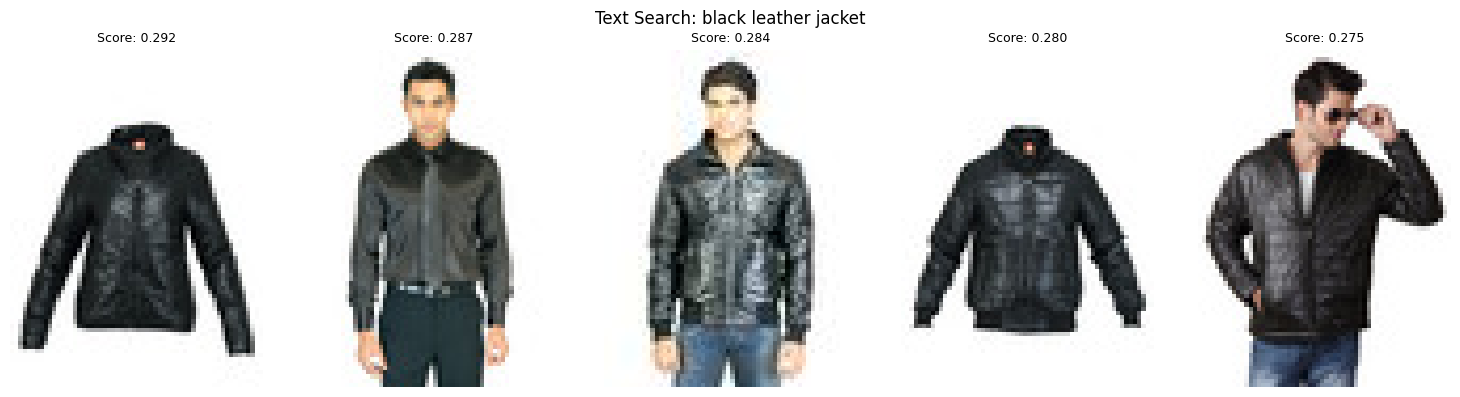

,id,productDisplayName,articleType,baseColour,similarity_score
0,17911,Nike Women Sptcas Black Jacket,Jackets,Black,0.292358
1,15975,Turtle Solid Men Black Shirt,Shirts,Black,0.286790
2,19340,United Colors of Benetton Men Solid Black Jacket,Jackets,Black,0.283873
3,17899,Nike Men Casual Black Jacket,Jackets,Black,0.280452
4,59106,Just Natural Men Black Jacket,Jackets,Black,0.274965


In [35]:
from PIL import Image
import matplotlib.pyplot as plt
import os

def display_search_results(results, title="Search Results"):
    """
    Display retrieved fashion products.
    """

    count = len(results)

    if count == 0:
        print("No results found.")
        return

    fig, axes = plt.subplots(
        1,
        count,
        figsize=(3 * count, 4)
    )

    if count == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, results.iterrows()):

        image_path = os.path.join(
            IMAGE_PATH,
            str(row["id"]) + ".jpg"
        )

        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)
        ax.axis("off")

        ax.set_title(
            f"Score: {row['similarity_score']:.3f}",
            fontsize=9
        )

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Try a natural language query
query = "black leather jacket"

results = text_to_image_search(
    query=query,
    top_k=5
)

display_search_results(
    results,
    title=f"Text Search: {query}"
)

display(
    results[
        [
            "id",
            "productDisplayName",
            "articleType",
            "baseColour",
            "similarity_score"
        ]
    ]
)


# Cell 34 — Image Embedding Function

In [36]:
from PIL import Image
import torch.nn.functional as F

def encode_image(image):
    """
    Convert a PIL image into a normalized CLIP embedding.
    """

    model.eval()

    inputs = processor(
        images=image.convert("RGB"),
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():

        vision_outputs = model.vision_model(
            pixel_values=pixel_values,
            return_dict=True
        )

        pooled_output = vision_outputs.pooler_output

        image_features = model.visual_projection(
            pooled_output
        )

        image_features = F.normalize(
            image_features,
            p=2,
            dim=-1
        )

    return image_features.cpu().numpy().astype(np.float32)


# Quick test using a dataset image
sample_image_path = image_paths[0]

sample_image = Image.open(sample_image_path).convert("RGB")

sample_embedding = encode_image(sample_image)

print("Embedding Shape:", sample_embedding.shape)
print("Embedding Norm:", np.linalg.norm(sample_embedding))

assert sample_embedding.shape == (1, 512)

print("\n Image embedding function is working!")


Embedding Shape: (1, 512)
Embedding Norm: 1.0

 Image embedding function is working!


# Cell 35 — Image-to-Image Search Function

In [37]:

def image_to_image_search(image, top_k=10):
    """
    Search for visually similar fashion products.
    """

    query_embedding = encode_image(image)

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    results = clean_df.iloc[indices[0]].copy()

    results["similarity_score"] = scores[0]
    results["faiss_id"] = indices[0]

    results = results.reset_index(drop=True)

    return results


print(" Image-to-Image Search function created!")


 Image-to-Image Search function created!


# Cell 36 — Test Image Search

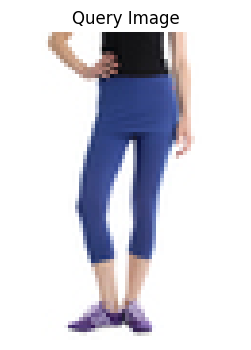

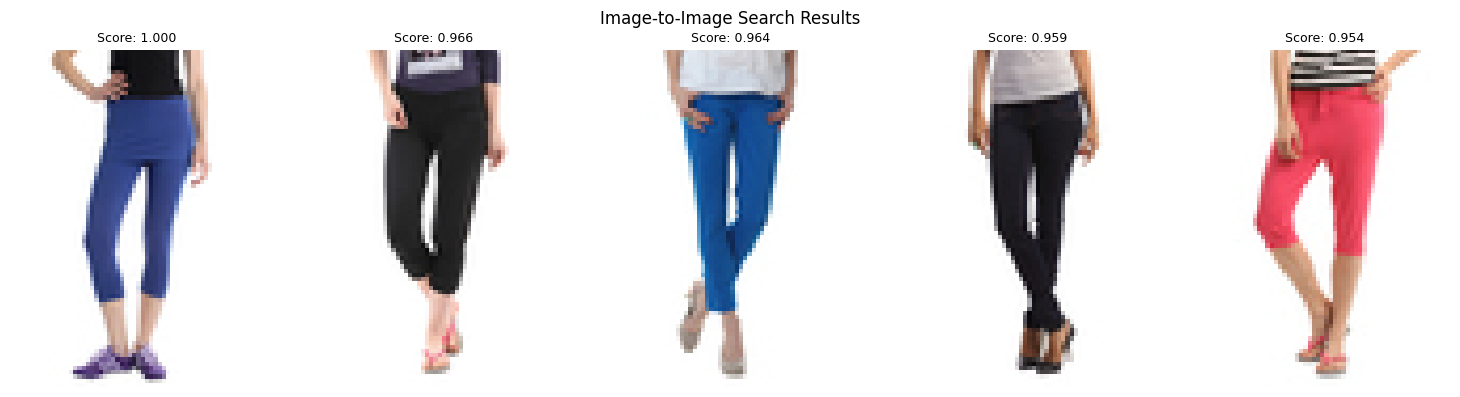

,id,productDisplayName,articleType,baseColour,similarity_score
0,28456,Urban Yoga Women Blue Skirt With Leggings,Skirts,Blue,1.000000
1,3483,ADIDAS Women Black Capri,Capris,Black,0.965768
2,48098,French Connection Women Blue Jeans,Jeans,Blue,0.963843
3,51591,Wrangler Women Navy Blue Giselle Jeans,Jeans,Navy Blue,0.959453
4,51993,Inaya Women Pink Lounge Shorts,Lounge Shorts,Pink,0.953662


In [38]:
query_image = Image.open(
    image_paths[100]
).convert("RGB")

plt.figure(figsize=(4, 4))
plt.imshow(query_image)
plt.axis("off")
plt.title("Query Image")
plt.show()

image_results = image_to_image_search(
    query_image,
    top_k=5
)

display_search_results(
    image_results,
    title="Image-to-Image Search Results"
)

display(
    image_results[
        [
            "id",
            "productDisplayName",
            "articleType",
            "baseColour",
            "similarity_score"
        ]
    ]
)


# Cell 37 — Evaluation Metrics

In [39]:
def precision_at_k(relevant, k):
    relevant = np.asarray(relevant[:k], dtype=bool)
    return relevant.sum() / k


def recall_at_k(relevant, total_relevant, k):
    relevant = np.asarray(relevant[:k], dtype=bool)

    if total_relevant == 0:
        return 0.0

    return relevant.sum() / total_relevant


def average_precision_at_k(relevant, total_relevant, k):
    relevant = np.asarray(relevant[:k], dtype=bool)

    if total_relevant == 0:
        return 0.0

    precision_values = []

    for position in range(1, k + 1):
        if relevant[position - 1]:
            precision_values.append(
                relevant[:position].sum() / position
            )

    if not precision_values:
        return 0.0

    return sum(precision_values) / min(total_relevant, k)


print(" Evaluation metrics implemented!")


 Evaluation metrics implemented!


# Cell 38 — Image Search Evaluation

In [40]:
import time

K = 10
NUM_EVAL_QUERIES = 100

# Sample query IDs
rng = np.random.default_rng(42)

sample_ids = rng.choice(
    len(clean_df),
    size=min(NUM_EVAL_QUERIES, len(clean_df)),
    replace=False
)

precision_scores = []
recall_scores = []
ap_scores = []
latencies = []

article_types = clean_df["articleType"].fillna("").astype(str).to_numpy()

for query_id in tqdm(sample_ids, desc="Evaluating"):

    query_vector = np.asarray(
        embeddings_map[query_id:query_id + 1],
        dtype=np.float32
    )

    start_time = time.perf_counter()

    scores, indices = index.search(
        query_vector,
        K + 1
    )

    latency = time.perf_counter() - start_time

    # Exclude the query image itself
    retrieved_ids = [
        int(idx)
        for idx in indices[0]
        if idx != query_id and idx >= 0
    ][:K]

    query_type = article_types[query_id]

    relevant = [
        article_types[idx] == query_type
        for idx in retrieved_ids
    ]

    total_relevant = int(
        np.sum(article_types == query_type) - 1
    )

    precision_scores.append(
        precision_at_k(relevant, K)
    )

    recall_scores.append(
        recall_at_k(relevant, total_relevant, K)
    )

    ap_scores.append(
        average_precision_at_k(relevant, total_relevant, K)
    )

    latencies.append(latency)


evaluation_results = {
    "Precision@10": np.mean(precision_scores),
    "Recall@10": np.mean(recall_scores),
    "MAP@10": np.mean(ap_scores),
    "Average Latency (ms)": np.mean(latencies) * 1000
}

print("\n Image Search Evaluation")
print("=" * 45)

for metric, value in evaluation_results.items():
    print(f"{metric}: {value:.4f}")


Evaluating:   0%|          | 0/100 [00:00<?, ?it/s]


 Image Search Evaluation
Precision@10: 0.7560
Recall@10: 0.0099
MAP@10: 0.7042
Average Latency (ms): 9.0623


# Cell 39 — Text Search Evaluation

In [41]:
common_types = (
    clean_df["articleType"]
    .dropna()
    .value_counts()
)

eval_types = common_types[
    common_types >= 20
].head(20).index.tolist()

text_precision = []
text_latencies = []

for article_type in tqdm(eval_types, desc="Text Evaluation"):

    query = f"a product photo of {article_type}"

    start_time = time.perf_counter()

    results = text_to_image_search(
        query,
        top_k=10
    )

    latency = time.perf_counter() - start_time

    relevant = (
        results["articleType"]
        .fillna("")
        .astype(str)
        .str.lower()
        .to_numpy()
        ==
        str(article_type).lower()
    )

    text_precision.append(
        precision_at_k(relevant, 10)
    )

    text_latencies.append(latency)


text_evaluation_results = {
    "Text Precision@10": np.mean(text_precision),
    "Average Text Latency (ms)": np.mean(text_latencies) * 1000
}

print("\n Text Search Evaluation")
print("=" * 45)

for metric, value in text_evaluation_results.items():
    print(f"{metric}: {value:.4f}")


Text Evaluation:   0%|          | 0/20 [00:00<?, ?it/s]


 Text Search Evaluation
Text Precision@10: 0.7800
Average Text Latency (ms): 36.6950


# Cell 40 — Evaluation Visualization

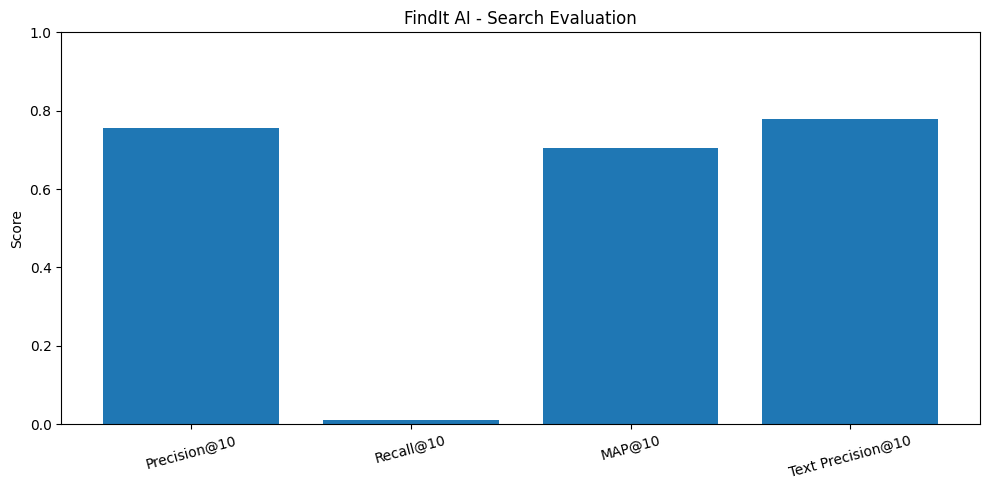

Image Average Latency: 9.06 ms
Text Average Latency: 36.69 ms


In [42]:
import matplotlib.pyplot as plt

metrics_to_plot = {
    "Precision@10": evaluation_results["Precision@10"],
    "Recall@10": evaluation_results["Recall@10"],
    "MAP@10": evaluation_results["MAP@10"],
    "Text Precision@10": text_evaluation_results["Text Precision@10"]
}

plt.figure(figsize=(10, 5))

plt.bar(
    list(metrics_to_plot.keys()),
    list(metrics_to_plot.values())
)

plt.title("FindIt AI - Search Evaluation")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Image Average Latency:",
      f"{evaluation_results['Average Latency (ms)']:.2f} ms")

print("Text Average Latency:",
      f"{text_evaluation_results['Average Text Latency (ms)']:.2f} ms")


# Cell 41 — Save Final Artifacts

In [43]:
import os
import json
import shutil
import faiss

ARTIFACTS_DIR = os.path.join(
    OUTPUT_DIR,
    "final_artifacts"
)

os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# 1. Save FAISS index
final_index_path = os.path.join(
    ARTIFACTS_DIR,
    "findit_faiss.index"
)

faiss.write_index(index, final_index_path)

# 2. Save metadata
metadata_path = os.path.join(
    ARTIFACTS_DIR,
    "metadata.csv"
)

clean_df.to_csv(
    metadata_path,
    index=False
)

# 3. Save CLIP model
model_dir = os.path.join(
    ARTIFACTS_DIR,
    "clip_model"
)

model.save_pretrained(model_dir)

# 4. Save CLIP processor
processor_dir = os.path.join(
    ARTIFACTS_DIR,
    "clip_processor"
)

processor.save_pretrained(processor_dir)

# 5. Save configuration
final_config = {
    "project_name": "FindIt AI",
    "model_name": MODEL_NAME,
    "embedding_dimension": EMBEDDING_DIM,
    "number_of_images": len(clean_df),
    "index_type": "IndexIDMap2(IndexFlatIP)",
    "similarity_metric": "Cosine Similarity",
    "embedding_normalization": "L2",
    "supported_search_modes": [
        "Text-to-Image",
        "Image-to-Image"
    ],
    "metadata_file": "metadata.csv",
    "index_file": "findit_faiss.index"
}

config_path = os.path.join(
    ARTIFACTS_DIR,
    "configuration.json"
)

with open(config_path, "w") as file:
    json.dump(final_config, file, indent=4)

# 6. Save evaluation results
all_evaluation_results = {
    "image_search": {
        key: float(value)
        for key, value in evaluation_results.items()
    },
    "text_search": {
        key: float(value)
        for key, value in text_evaluation_results.items()
    }
}

evaluation_path = os.path.join(
    ARTIFACTS_DIR,
    "evaluation_results.json"
)

with open(evaluation_path, "w") as file:
    json.dump(all_evaluation_results, file, indent=4)

print(" Final artifacts saved successfully!")
print("\nSaved components:")

for item in os.listdir(ARTIFACTS_DIR):
    print(item)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Final artifacts saved successfully!

Saved components:
evaluation_results.json
findit_faiss.index
configuration.json
clip_model
metadata.csv
clip_processor


# Cell 42 — Final Artifacts Validation

In [44]:
required_artifacts = [
    "findit_faiss.index",
    "metadata.csv",
    "clip_model",
    "clip_processor",
    "configuration.json",
    "evaluation_results.json"
]

print(" Final Artifact Validation")
print("=" * 50)

for artifact in required_artifacts:

    artifact_path = os.path.join(
        ARTIFACTS_DIR,
        artifact
    )

    exists = os.path.exists(artifact_path)

    print(
        f"{'✅' if exists else '❌'} {artifact}"
    )

    assert exists, f"Missing artifact: {artifact}"


# Reload index independently
loaded_index = faiss.read_index(
    os.path.join(
        ARTIFACTS_DIR,
        "findit_faiss.index"
    )
)

loaded_metadata = pd.read_csv(
    os.path.join(
        ARTIFACTS_DIR,
        "metadata.csv"
    )
)

assert loaded_index.ntotal == len(loaded_metadata)

print("\nIndex Vectors:", loaded_index.ntotal)
print("Metadata Rows:", len(loaded_metadata))
print("Index Dimension:", loaded_index.d)

print("\n All artifacts validated successfully!")


 Final Artifact Validation
✅ findit_faiss.index
✅ metadata.csv
✅ clip_model
✅ clip_processor
✅ configuration.json
✅ evaluation_results.json

Index Vectors: 44419
Metadata Rows: 44419
Index Dimension: 512

 All artifacts validated successfully!


# Cell 43 — Create Streamlit App

In [45]:
app_code = r'''
import os
import streamlit as st
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import faiss

from PIL import Image
from transformers import CLIPModel, CLIPProcessor


# ==========================================
# CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="FindIt AI",
    page_icon="🔎",
    layout="wide"
)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
ARTIFACTS_DIR = os.path.join(BASE_DIR, "final_artifacts")

INDEX_PATH = os.path.join(
    ARTIFACTS_DIR,
    "findit_faiss.index"
)

METADATA_PATH = os.path.join(
    ARTIFACTS_DIR,
    "metadata.csv"
)

MODEL_PATH = os.path.join(
    ARTIFACTS_DIR,
    "clip_model"
)

PROCESSOR_PATH = os.path.join(
    ARTIFACTS_DIR,
    "clip_processor"
)


# ==========================================
# LOAD MODELS AND DATA
# ==========================================

@st.cache_resource
def load_resources():

    device = torch.device("cpu")

    model = CLIPModel.from_pretrained(MODEL_PATH)
    processor = CLIPProcessor.from_pretrained(PROCESSOR_PATH)

    model.to(device)
    model.eval()

    index = faiss.read_index(INDEX_PATH)
    metadata = pd.read_csv(METADATA_PATH)

    return model, processor, index, metadata, device


try:
    model, processor, index, metadata, device = load_resources()
except Exception as error:
    st.error(f"Could not load project artifacts: {error}")
    st.stop()


# ==========================================
# IMAGE DIRECTORY
# ==========================================

default_image_dir = "/kaggle/input/datasets/paramaggarwal/fashion-product-images-small/images"

image_dir = st.sidebar.text_input(
    "Dataset Images Folder",
    value=default_image_dir
)


# ==========================================
# EMBEDDING FUNCTIONS
# ==========================================

def encode_text(text):

    inputs = processor(
        text=[text],
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs.get("attention_mask"),
            return_dict=True
        )

        features = model.text_projection(
            outputs.pooler_output
        )

        features = F.normalize(
            features,
            p=2,
            dim=-1
        )

    return features.cpu().numpy().astype(np.float32)


def encode_image(image):

    inputs = processor(
        images=image.convert("RGB"),
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():

        outputs = model.vision_model(
            pixel_values=pixel_values,
            return_dict=True
        )

        features = model.visual_projection(
            outputs.pooler_output
        )

        features = F.normalize(
            features,
            p=2,
            dim=-1
        )

    return features.cpu().numpy().astype(np.float32)


# ==========================================
# SEARCH FUNCTION
# ==========================================

def search_products(query_embedding, top_k):

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    results = metadata.iloc[indices[0]].copy()

    results["similarity_score"] = scores[0]

    return results.reset_index(drop=True)


# ==========================================
# DISPLAY RESULTS
# ==========================================

def display_results(results):

    if len(results) == 0:
        st.warning("No products found.")
        return

    columns = st.columns(5)

    for i, (_, row) in enumerate(results.iterrows()):

        image_path = os.path.join(
            image_dir,
            str(row["id"]) + ".jpg"
        )

        with columns[i % 5]:

            if os.path.exists(image_path):
                st.image(image_path, use_container_width=True)
            else:
                st.warning("Image unavailable")

            st.caption(str(row.get("productDisplayName", "Product")))

            st.write(
                f"**Similarity:** {row['similarity_score']:.3f}"
            )

            st.caption(
                f"{row.get('articleType', '')} | "
                f"{row.get('baseColour', '')}"
            )


# ==========================================
# USER INTERFACE
# ==========================================

st.title("🔎 FindIt AI")
st.subheader("AI-Powered Fashion Visual Search Engine")

st.write(
    "Search fashion products using natural language "
    "or upload an image to find visually similar products."
)

st.sidebar.header("Search Settings")

search_mode = st.sidebar.radio(
    "Search Mode",
    ["Text Search", "Image Search"]
)

top_k = st.sidebar.slider(
    "Number of Results",
    min_value=5,
    max_value=20,
    value=10
)


if search_mode == "Text Search":

    st.header("📝 Text-to-Image Search")

    query = st.text_input(
        "Describe the product",
        placeholder="Example: black leather jacket"
    )

    if st.button("Search Products"):

        if query.strip():

            with st.spinner("Searching products..."):

                query_embedding = encode_text(query)

                results = search_products(
                    query_embedding,
                    top_k
                )

            st.success(f"Found {len(results)} results")
            display_results(results)

        else:
            st.warning("Please enter a search description.")


else:

    st.header("🖼️ Image-to-Image Search")

    uploaded_file = st.file_uploader(
        "Upload a fashion image",
        type=["jpg", "jpeg", "png"]
    )

    if uploaded_file is not None:

        query_image = Image.open(uploaded_file).convert("RGB")

        st.image(
            query_image,
            caption="Uploaded Query Image",
            width=250
        )

        if st.button("Find Similar Products"):

            with st.spinner("Finding similar products..."):

                query_embedding = encode_image(query_image)

                results = search_products(
                    query_embedding,
                    top_k
                )

            st.success(f"Found {len(results)} results")
            display_results(results)


st.divider()

st.caption(
    "FindIt AI | Powered by OpenAI CLIP and FAISS"
)
'''

app_path = os.path.join(
    "/kaggle/working",
    "app.py"
)

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_code)

print(" Streamlit app created!")
print("App path:", app_path)
print("App size:", os.path.getsize(app_path), "bytes")


 Streamlit app created!
App path: /kaggle/working/app.py
App size: 6500 bytes


# Cell 44 — Create Project Bundle

In [46]:
import zipfile
import os

PROJECT_DIR = "/kaggle/working/FindIt_AI_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

# Copy app
shutil.copy2(
    app_path,
    os.path.join(PROJECT_DIR, "app.py")
)

# Copy final artifacts
project_artifacts = os.path.join(
    PROJECT_DIR,
    "final_artifacts"
)

if os.path.exists(project_artifacts):
    shutil.rmtree(project_artifacts)

shutil.copytree(
    ARTIFACTS_DIR,
    project_artifacts
)

# Create requirements
requirements = """
streamlit
torch
transformers
faiss-cpu
pandas
numpy
Pillow
"""

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w"
) as file:
    file.write(requirements.strip() + "\n")

# Create README
readme = """
# FindIt AI

AI-powered fashion visual search engine.

## Features
- Text-to-Image Search
- Image-to-Image Search
- CLIP Embeddings
- FAISS Similarity Search

## Run

Install dependencies:

pip install -r requirements.txt

Run application:

streamlit run app.py

The application requires the original fashion dataset images.
Set the correct image directory in the sidebar.
"""

with open(
    os.path.join(PROJECT_DIR, "README.md"),
    "w"
) as file:
    file.write(readme.strip() + "\n")

# Zip project
ZIP_PATH = "/kaggle/working/FindIt_AI_Project.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files in os.walk(PROJECT_DIR):

        for filename in files:

            full_path = os.path.join(root, filename)

            relative_path = os.path.relpath(
                full_path,
                PROJECT_DIR
            )

            zip_file.write(
                full_path,
                arcname=os.path.join(
                    "FindIt_AI_Project",
                    relative_path
                )
            )

print(" Project bundle created!")
print("ZIP:", ZIP_PATH)
print(
    "Size:",
    f"{os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB"
)


 Project bundle created!
ZIP: /kaggle/working/FindIt_AI_Project.zip
Size: 455.71 MB


# Cell 45 — Final Project Report

In [47]:
print("=" * 60)
print("FINDIT AI - FINAL PROJECT REPORT")
print("=" * 60)

print("\nDATASET")
print(f"Total Products: {len(clean_df):,}")

print("\nMODEL")
print(f"Model: {MODEL_NAME}")
print(f"Embedding Dimension: {EMBEDDING_DIM}")

print("\nSEARCH ENGINE")
print(f"FAISS Vectors: {index.ntotal:,}")
print("Index: IndexIDMap2(IndexFlatIP)")
print("Similarity: Cosine Similarity")

print("\nIMAGE SEARCH EVALUATION")

for metric, value in evaluation_results.items():
    print(f"{metric}: {value:.4f}")

print("\nTEXT SEARCH EVALUATION")

for metric, value in text_evaluation_results.items():
    print(f"{metric}: {value:.4f}")

print("\nDELIVERABLES")
print(f"Artifacts: {ARTIFACTS_DIR}")
print(f"Streamlit App: {app_path}")
print(f"Project ZIP: {ZIP_PATH}")

print("\n" + "=" * 60)
print("FINDIT AI PIPELINE COMPLETED!")
print("=" * 60)


FINDIT AI - FINAL PROJECT REPORT

DATASET
Total Products: 44,419

MODEL
Model: openai/clip-vit-base-patch32
Embedding Dimension: 512

SEARCH ENGINE
FAISS Vectors: 44,419
Index: IndexIDMap2(IndexFlatIP)
Similarity: Cosine Similarity

IMAGE SEARCH EVALUATION
Precision@10: 0.7560
Recall@10: 0.0099
MAP@10: 0.7042
Average Latency (ms): 9.0623

TEXT SEARCH EVALUATION
Text Precision@10: 0.7800
Average Text Latency (ms): 36.6950

DELIVERABLES
Artifacts: /kaggle/working/findit_artifacts/final_artifacts
Streamlit App: /kaggle/working/app.py
Project ZIP: /kaggle/working/FindIt_AI_Project.zip

FINDIT AI PIPELINE COMPLETED!


# Cell 46 — Build the Enhanced Streamlit App

In [48]:
import os

PROJECT_DIR = "/kaggle/working/FindIt_AI_Project"
ARTIFACTS_DIR = os.path.join(PROJECT_DIR, "final_artifacts")

os.makedirs(PROJECT_DIR, exist_ok=True)

app_code = r'''
import os
import streamlit as st
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import faiss

from PIL import Image
from transformers import CLIPModel, CLIPProcessor


# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="FindIt AI | Visual Search",
    page_icon="🔎",
    layout="wide",
    initial_sidebar_state="expanded"
)

st.markdown("""
<style>
    .main-title {
        font-size: 2.7rem;
        font-weight: 800;
        margin-bottom: 0;
    }
    .subtitle {
        color: #9CA3AF;
        font-size: 1.05rem;
        margin-top: 0.2rem;
        margin-bottom: 1.5rem;
    }
    .result-card {
        padding: 12px;
        border: 1px solid rgba(128,128,128,0.25);
        border-radius: 12px;
        margin-bottom: 12px;
    }
    .score {
        font-weight: 700;
        color: #16A34A;
    }
</style>
""", unsafe_allow_html=True)


# ==========================================
# PATHS
# ==========================================

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
ARTIFACTS_DIR = os.path.join(BASE_DIR, "final_artifacts")

INDEX_PATH = os.path.join(
    ARTIFACTS_DIR, "findit_faiss.index"
)

METADATA_PATH = os.path.join(
    ARTIFACTS_DIR, "metadata.csv"
)

MODEL_PATH = os.path.join(
    ARTIFACTS_DIR, "clip_model"
)

PROCESSOR_PATH = os.path.join(
    ARTIFACTS_DIR, "clip_processor"
)


# ==========================================
# RESOURCE LOADING
# ==========================================

@st.cache_resource
def load_resources():

    required_paths = [
        INDEX_PATH,
        METADATA_PATH,
        MODEL_PATH,
        PROCESSOR_PATH
    ]

    missing = [
        path for path in required_paths
        if not os.path.exists(path)
    ]

    if missing:
        raise FileNotFoundError(
            "Missing project files:\n" + "\n".join(missing)
        )

    device = torch.device("cpu")

    model = CLIPModel.from_pretrained(
        MODEL_PATH,
        local_files_only=True
    )

    processor = CLIPProcessor.from_pretrained(
        PROCESSOR_PATH,
        local_files_only=True
    )

    model.to(device)
    model.eval()

    index = faiss.read_index(INDEX_PATH)

    metadata = pd.read_csv(
        METADATA_PATH,
        dtype={"id": str}
    )

    if len(metadata) != index.ntotal:
        raise ValueError(
            "Metadata rows do not match FAISS index vectors."
        )

    return model, processor, index, metadata, device


try:
    with st.spinner("Loading FindIt AI models and search index..."):
        model, processor, index, metadata, device = load_resources()

except Exception as error:
    st.error("Unable to load FindIt AI resources.")
    st.exception(error)
    st.stop()


# ==========================================
# IMAGE DIRECTORY
# ==========================================

default_image_dir = os.environ.get(
    "FINDIT_IMAGE_DIR",
    ""
)

st.sidebar.title("⚙️ Search Settings")

image_dir = st.sidebar.text_input(
    "Dataset Images Folder",
    value=default_image_dir,
    placeholder="Path to the folder containing product JPG images"
)

if not image_dir or not os.path.isdir(image_dir):
    st.sidebar.warning(
        "Set a valid dataset images folder to display product images."
    )


# ==========================================
# FILTER OPTIONS
# ==========================================

def get_filter_options(column):

    if column not in metadata.columns:
        return ["All"]

    values = (
        metadata[column]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    return ["All"] + sorted(values)


st.sidebar.divider()
st.sidebar.subheader("Product Filters")

gender_filter = st.sidebar.selectbox(
    "Gender",
    get_filter_options("gender")
)

category_filter = st.sidebar.selectbox(
    "Category",
    get_filter_options("articleType")
)

color_filter = st.sidebar.selectbox(
    "Color",
    get_filter_options("baseColour")
)

top_k = st.sidebar.slider(
    "Number of Results",
    min_value=5,
    max_value=30,
    value=10
)


# ==========================================
# EMBEDDING FUNCTIONS
# ==========================================

def encode_text(text):

    inputs = processor(
        text=[text],
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model.text_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs.get("attention_mask"),
            return_dict=True
        )

        features = model.text_projection(
            outputs.pooler_output
        )

        features = F.normalize(
            features,
            p=2,
            dim=-1
        )

    return features.cpu().numpy().astype(np.float32)


def encode_image(image):

    inputs = processor(
        images=image.convert("RGB"),
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():

        outputs = model.vision_model(
            pixel_values=pixel_values,
            return_dict=True
        )

        features = model.visual_projection(
            outputs.pooler_output
        )

        features = F.normalize(
            features,
            p=2,
            dim=-1
        )

    return features.cpu().numpy().astype(np.float32)


# ==========================================
# SEARCH + FILTERING
# ==========================================

def search_products(query_embedding, requested_k):

    # Search the complete index so filters are not limited
    # to an arbitrary small candidate pool.
    scores, indices = index.search(
        query_embedding,
        index.ntotal
    )

    valid = indices[0] >= 0

    retrieved_ids = indices[0][valid].astype(int)
    retrieved_scores = scores[0][valid]

    results = metadata.iloc[retrieved_ids].copy()

    results["similarity_score"] = retrieved_scores
    results["faiss_id"] = retrieved_ids

    if gender_filter != "All" and "gender" in results.columns:
        results = results[
            results["gender"].astype(str) == gender_filter
        ]

    if category_filter != "All" and "articleType" in results.columns:
        results = results[
            results["articleType"].astype(str) == category_filter
        ]

    if color_filter != "All" and "baseColour" in results.columns:
        results = results[
            results["baseColour"].astype(str) == color_filter
        ]

    results = results.sort_values(
        "similarity_score",
        ascending=False
    )

    return results.head(requested_k).reset_index(drop=True)


# ==========================================
# PRODUCT IMAGE PATH
# ==========================================

def get_product_image_path(product_id):

    if not image_dir:
        return None

    product_id = str(product_id).strip()

    # Handle numeric IDs that may have a trailing .0
    if product_id.endswith(".0"):
        product_id = product_id[:-2]

    return os.path.join(
        image_dir,
        f"{product_id}.jpg"
    )


# ==========================================
# DISPLAY RESULTS
# ==========================================

def display_results(results):

    if results.empty:
        st.warning(
            "No products matched the current search and filters."
        )
        return

    st.success(f"{len(results)} products found")

    columns_per_row = 5

    for start in range(0, len(results), columns_per_row):

        row = results.iloc[
            start:start + columns_per_row
        ]

        columns = st.columns(columns_per_row)

        for column, (_, product) in zip(columns, row.iterrows()):

            with column:

                image_path = get_product_image_path(
                    product["id"]
                )

                if image_path and os.path.isfile(image_path):
                    st.image(
                        image_path,
                        use_container_width=True
                    )
                else:
                    st.info("Product image unavailable")

                product_name = product.get(
                    "productDisplayName",
                    "Fashion Product"
                )

                st.markdown(
                    f"**{product_name}**"
                )

                score = float(
                    product["similarity_score"]
                )

                st.markdown(
                    f'<p class="score">Similarity: {score:.3f}</p>',
                    unsafe_allow_html=True
                )

                article_type = product.get("articleType", "")
                color = product.get("baseColour", "")
                gender = product.get("gender", "")

                st.caption(
                    f"{article_type} · {color} · {gender}"
                )


# ==========================================
# HEADER
# ==========================================

st.markdown(
    '<p class="main-title">🔎 FindIt AI</p>',
    unsafe_allow_html=True
)

st.markdown(
    '<p class="subtitle">'
    'AI-Powered Fashion Visual Search Engine · Powered by CLIP + FAISS'
    '</p>',
    unsafe_allow_html=True
)

metric1, metric2, metric3 = st.columns(3)

metric1.metric(
    "Fashion Products",
    f"{len(metadata):,}"
)

metric2.metric(
    "Indexed Vectors",
    f"{index.ntotal:,}"
)

metric3.metric(
    "Embedding Dimension",
    str(index.d)
)

st.divider()


# ==========================================
# SEARCH INTERFACE
# ==========================================

search_mode = st.radio(
    "Choose your search method",
    ["📝 Search by Text", "🖼️ Search by Image"],
    horizontal=True
)


if search_mode == "📝 Search by Text":

    st.subheader("Describe the product you're looking for")

    with st.form("text_search_form"):

        query = st.text_input(
            "Product description",
            placeholder="Example: black leather jacket"
        )

        submitted = st.form_submit_button(
            "🔍 Search Products",
            use_container_width=True
        )

    if submitted:

        if not query.strip():
            st.warning("Please enter a product description.")

        else:

            with st.spinner("Finding visually relevant products..."):

                query_embedding = encode_text(query)

                results = search_products(
                    query_embedding,
                    top_k
                )

            st.subheader("Search Results")
            display_results(results)


else:

    st.subheader("Upload a product image")

    uploaded_file = st.file_uploader(
        "Choose an image",
        type=["jpg", "jpeg", "png", "webp"]
    )

    if uploaded_file is not None:

        try:
            query_image = Image.open(
                uploaded_file
            ).convert("RGB")

            st.image(
                query_image,
                caption="Your query image",
                width=250
            )

            if st.button(
                "🔍 Find Similar Products",
                use_container_width=True
            ):

                with st.spinner("Searching for similar products..."):

                    query_embedding = encode_image(query_image)

                    results = search_products(
                        query_embedding,
                        top_k
                    )

                st.subheader("Similar Products")
                display_results(results)

        except Exception as error:
            st.error("Could not process the uploaded image.")
            st.exception(error)


# ==========================================
# FOOTER
# ==========================================

st.divider()

st.caption(
    "FindIt AI | CLIP Image Embeddings | FAISS Similarity Search"
)
'''

app_path = os.path.join(PROJECT_DIR, "app.py")

with open(app_path, "w", encoding="utf-8") as file:
    file.write(app_code)

print(" Enhanced Streamlit app created!")
print("App:", app_path)
print("Size:", f"{os.path.getsize(app_path):,} bytes")


 Enhanced Streamlit app created!
App: /kaggle/working/FindIt_AI_Project/app.py
Size: 12,007 bytes


# Cell 47 — Validate the Application

In [49]:
import os
import py_compile

required_paths = {
    "Application": os.path.join(PROJECT_DIR, "app.py"),
    "FAISS Index": os.path.join(ARTIFACTS_DIR, "findit_faiss.index"),
    "Metadata": os.path.join(ARTIFACTS_DIR, "metadata.csv"),
    "CLIP Model": os.path.join(ARTIFACTS_DIR, "clip_model"),
    "CLIP Processor": os.path.join(ARTIFACTS_DIR, "clip_processor"),
    "Configuration": os.path.join(ARTIFACTS_DIR, "configuration.json"),
    "Evaluation": os.path.join(ARTIFACTS_DIR, "evaluation_results.json")
}

print("FINDIT AI - APPLICATION VALIDATION")
print("=" * 55)

for name, path in required_paths.items():

    exists = os.path.exists(path)

    print(f"{'✅' if exists else '❌'} {name}")

    assert exists, f"Missing: {name}"

# Python syntax validation
py_compile.compile(
    os.path.join(PROJECT_DIR, "app.py"),
    doraise=True
)

print("\napp.py syntax is valid!")

# Validate metadata and index
check_metadata = pd.read_csv(
    os.path.join(ARTIFACTS_DIR, "metadata.csv"),
    dtype={"id": str}
)

check_index = faiss.read_index(
    os.path.join(ARTIFACTS_DIR, "findit_faiss.index")
)

assert len(check_metadata) == check_index.ntotal

print("Metadata Records:", f"{len(check_metadata):,}")
print("FAISS Vectors:", f"{check_index.ntotal:,}")
print("Index Dimension:", check_index.d)

print("\nApplication validation passed!")


FINDIT AI - APPLICATION VALIDATION
✅ Application
✅ FAISS Index
✅ Metadata
✅ CLIP Model
✅ CLIP Processor
✅ Configuration
✅ Evaluation

app.py syntax is valid!
Metadata Records: 44,419
FAISS Vectors: 44,419
Index Dimension: 512

Application validation passed!


# Cell 48 — Rebuild the Final Project ZIP

In [50]:

import os
import shutil
import zipfile

# Requirements
requirements = """
streamlit
torch
transformers
faiss-cpu
pandas
numpy
Pillow
"""

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(requirements.strip() + "\n")


# README
readme = """
# FindIt AI

AI-Powered Fashion Visual Search Engine.

## Features

- Text-to-Image Search
- Image-to-Image Search
- CLIP-based semantic image embeddings
- FAISS similarity search
- Product filtering by gender, category, and color
- Similarity scores and ranked results

## Project Architecture

1. Fashion product images and metadata
2. Data cleaning and validation
3. CLIP image embedding extraction
4. FAISS vector indexing
5. Text and image retrieval
6. Streamlit user interface

## Requirements

- Python 3.10+
- Dependencies listed in requirements.txt

## Installation

Create and activate a virtual environment, then run:

pip install -r requirements.txt

## Dataset Images

Download the Fashion Product Images (Small) dataset from Kaggle:

https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small

Extract the dataset and locate its images folder.

## Run the Application

Run:

streamlit run app.py

Enter the full path to the dataset images folder in the application sidebar.

## Search Modes

- Text Search: describe a fashion product using natural language.
- Image Search: upload an image to retrieve visually similar products.

## Model

openai/clip-vit-base-patch32

Embedding dimension: 512

## Search Engine

FAISS IndexIDMap2(IndexFlatIP)

Similarity metric: Cosine Similarity over L2-normalized embeddings.

## Evaluation

The current evaluation uses articleType as a proxy relevance label.
It should not be interpreted as human-judged semantic relevance.

## Important

The project ZIP includes the model, processor, metadata, and FAISS index.
The original dataset images are not included.
"""

with open(
    os.path.join(PROJECT_DIR, "README.md"),
    "w",
    encoding="utf-8"
) as file:
    file.write(readme.strip() + "\n")


# Remove previous ZIP if it exists
ZIP_PATH = "/kaggle/working/FindIt_AI_Project.zip"

if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)


# Create updated ZIP
with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files in os.walk(PROJECT_DIR):

        # Avoid including Python cache files
        dirs[:] = [
            directory for directory in dirs
            if directory != "__pycache__"
        ]

        for filename in files:

            if filename.endswith(".pyc"):
                continue

            full_path = os.path.join(root, filename)

            relative_path = os.path.relpath(
                full_path,
                PROJECT_DIR
            )

            zip_file.write(
                full_path,
                arcname=os.path.join(
                    "FindIt_AI_Project",
                    relative_path
                )
            )


print("Updated project package created!")
print("ZIP Path:", ZIP_PATH)
print(
    "ZIP Size:",
    f"{os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB"
)
print("\nPackage contents:")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    for name in zip_file.namelist():
        print(name)


Updated project package created!
ZIP Path: /kaggle/working/FindIt_AI_Project.zip
ZIP Size: 455.71 MB

Package contents:
FindIt_AI_Project/app.py
FindIt_AI_Project/README.md
FindIt_AI_Project/requirements.txt
FindIt_AI_Project/final_artifacts/evaluation_results.json
FindIt_AI_Project/final_artifacts/findit_faiss.index
FindIt_AI_Project/final_artifacts/configuration.json
FindIt_AI_Project/final_artifacts/metadata.csv
FindIt_AI_Project/final_artifacts/clip_model/config.json
FindIt_AI_Project/final_artifacts/clip_model/model.safetensors
FindIt_AI_Project/final_artifacts/clip_processor/tokenizer_config.json
FindIt_AI_Project/final_artifacts/clip_processor/processor_config.json
FindIt_AI_Project/final_artifacts/clip_processor/tokenizer.json


# Cell 49 — Split Project ZIP

In [51]:
import os
import math

ZIP_PATH = "/kaggle/working/FindIt_AI_Project.zip"
PARTS_DIR = "/kaggle/working/FindIt_AI_Download_Parts"

assert os.path.exists(ZIP_PATH), "Project ZIP not found!"

os.makedirs(PARTS_DIR, exist_ok=True)

PART_SIZE = 100 * 1024 * 1024  # 100 MB

file_size = os.path.getsize(ZIP_PATH)
total_parts = math.ceil(file_size / PART_SIZE)

print("Splitting FindIt AI Project")
print("=" * 45)
print(f"Original ZIP: {file_size / (1024**2):.2f} MB")
print(f"Total Parts: {total_parts}")

with open(ZIP_PATH, "rb") as source:

    for part_number in range(total_parts):

        part_path = os.path.join(
            PARTS_DIR,
            f"FindIt_AI_Part_{part_number + 1:02d}.bin"
        )

        data = source.read(PART_SIZE)

        with open(part_path, "wb") as part_file:
            part_file.write(data)

        print(
            f"Part {part_number + 1}/{total_parts}: "
            f"{os.path.getsize(part_path) / (1024**2):.2f} MB"
        )

print("\nSplitting completed!")
print("Parts folder:", PARTS_DIR)


Splitting FindIt AI Project
Original ZIP: 455.71 MB
Total Parts: 5
Part 1/5: 100.00 MB
Part 2/5: 100.00 MB
Part 3/5: 100.00 MB
Part 4/5: 100.00 MB
Part 5/5: 55.71 MB

Splitting completed!
Parts folder: /kaggle/working/FindIt_AI_Download_Parts


# Cell 50 — Verify All Parts

In [52]:
import os

parts = sorted(
    [
        f for f in os.listdir(PARTS_DIR)
        if f.endswith(".bin")
    ]
)

total_size = sum(
    os.path.getsize(os.path.join(PARTS_DIR, f))
    for f in parts
)

original_size = os.path.getsize(ZIP_PATH)

print("DOWNLOAD PARTS REPORT")
print("=" * 45)

for part in parts:
    path = os.path.join(PARTS_DIR, part)
    print(f"{part} | {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nParts:", len(parts))
print("Original:", original_size)
print("Parts Total:", total_size)

assert total_size == original_size
assert len(parts) > 0

print("\nAll parts verified!")


DOWNLOAD PARTS REPORT
FindIt_AI_Part_01.bin | 100.00 MB
FindIt_AI_Part_02.bin | 100.00 MB
FindIt_AI_Part_03.bin | 100.00 MB
FindIt_AI_Part_04.bin | 100.00 MB
FindIt_AI_Part_05.bin | 55.71 MB

Parts: 5
Original: 477844531
Parts Total: 477844531

All parts verified!
